# ¿Es asequible el precio de la vivienda para el cubano promedio?
## Análisis de anuncios inmobiliarios de La Habana

**Proyecto académico - Ciencia de Datos (ICD 2026)**
Caso de estudio: La Habana, Cuba

Este notebook tiene como objetivo analizar si el precio de la vivienda en La Habana es asequible para el cubano promedio, a partir de anuncios publicados en portales inmobiliarios (GAOS y Revolico).

El análisis busca responder a las siguientes preguntas:
1. ¿Cuánto cuesta una casa en La Habana?
2. ¿Cuánto cuesta un apartamento en La Habana?
3. ¿Cómo se distribuyen los precios de las viviendas entre los municipios de La Habana?
4. ¿Qué características aparecen con mayor frecuencia en los anuncios cuyo precio supera la mediana?
5. ¿Cómo se relacionan los precios de las viviendas con los salarios establecidos oficialmente?
6. ¿Cuál es el inmueble más habitual y cuánto cuesta en relación con el salario mínimo?

**Nota metodológica:** En este proyecto no se calcula el precio por metro cuadrado, ya que la información de áreas es incompleta, el tipo de superficie declarada no está identificado en ningún anuncio y sus unidades no están verificadas (ver sección 6.2). Tampoco se intenta determinar qué características hacen que un precio sea superior o inferior a la mediana, ya que los datos disponibles no permiten establecer esa relación de manera fiable.

**En esta primera etapa:** Cargamos los datos y realizamos una primera exploración para comprender qué información tenemos disponible.


## 2. Importaciones

Importamos las librerías necesarias para esta primera fase de exploración de datos.

In [1]:
import os
from pathlib import Path

# Sube desde el directorio actual hasta encontrar la raíz del proyecto
carpeta = Path.cwd()
while not all((carpeta / nombre).is_dir() for nombre in ("src", "data", "notebooks")):
    if carpeta.parent == carpeta:
        raise RuntimeError(
            "No se encontró la raíz del proyecto: se esperaba una carpeta con 'src', 'data' y 'notebooks'."
        )
    carpeta = carpeta.parent

os.chdir(carpeta)
print("Directorio de trabajo establecido en la raíz del proyecto")

Directorio de trabajo establecido en la raíz del proyecto


In [2]:
import pandas as pd
import json


## 3. Carga de datos

Cargamos el archivo unificado que contiene los anuncios de GAOS y Revolico. El archivo tiene una estructura anidada: los anuncios se encuentran bajo la clave `'datos'`, mientras que el nivel superior contiene metadatos de la captura (fecha, fuente, etc.).

In [3]:
ruta_archivo = 'data/processed/anuncios/unificado_procesado_83924fda_20261115_034632.json'

with open(ruta_archivo, 'r', encoding='utf-8') as f:
    datos = json.load(f)

anuncios = datos['datos']
df = pd.DataFrame(anuncios)

print(f'Anuncios cargados: {len(df)}')
print(f'Columnas: {df.columns.tolist()}')

Anuncios cargados: 307
Columnas: ['id_fuente', 'url', 'fecha_captura', 'fecha_publicacion', 'fecha_actualizacion', 'provincia', 'municipio', 'reparto', 'direccion_texto', 'tipo_operacion', 'tipo_inmueble', 'area_m2', 'tipo_area', 'habitaciones', 'banos', 'planta', 'estado_conservacion', 'amueblado', 'precio', 'moneda', 'precio_usd', 'tasa_conversion_usd', 'tasa_fecha', 'tasa_fuente', 'precio_m2_usd', 'tasa_id', 'titulo', 'descripcion', 'vendedor_tipo', 'estado_parseo', 'notas_calidad', 'es_posible_duplicado', 'duplicado_grupo', 'fuente']


## 4. Primera exploración de datos

En esta sección realizamos una primera revisión de los datos cargados para entender su estructura y calidad.

In [4]:
# Dimensiones del DataFrame
print('Dimensiones del DataFrame:')
print(df.shape)
print(f'Filas (anuncios): {df.shape[0]}')
print(f'Columnas: {df.shape[1]}')

Dimensiones del DataFrame:
(307, 34)
Filas (anuncios): 307
Columnas: 34


In [5]:
# Primeros registros (sin URL, título ni descripción)
print('Primeros 5 anuncios:')
columnas_vista = [
    "id_fuente", "fuente", "tipo_operacion", "tipo_inmueble",
    "municipio", "precio", "moneda",
]
df[columnas_vista].head()


Primeros 5 anuncios:


,id_fuente,fuente,tipo_operacion,tipo_inmueble,municipio,precio,moneda
0,af158783-d598-415e-9d24-f2a13859c02a,gaos,venta,apartamento,San Miguel del Padrón,3000.0,USD
1,77da67f2-d266-4c71-a83d-a1feb7ec272f,gaos,venta,casa,San Miguel del Padrón,5500.0,USD
2,9508aa9a-587c-4132-8d1f-6ba414de0152,gaos,venta,apartamento,Habana Vieja,15000.0,USD
3,802d26bb-29a3-4dc6-b430-6313b0a88b6d,gaos,venta,casa,Playa,20000.0,USD
4,e10a20b4-1e90-4ab9-aa5b-627993f58631,gaos,venta,casa,NaN,190000.0,USD


In [6]:
# Nombres de las columnas
print('Columnas del DataFrame:')
for columna in df.columns:
    print(f'  - {columna}')

Columnas del DataFrame:
  - id_fuente
  - url
  - fecha_captura
  - fecha_publicacion
  - fecha_actualizacion
  - provincia
  - municipio
  - reparto
  - direccion_texto
  - tipo_operacion
  - tipo_inmueble
  - area_m2
  - tipo_area
  - habitaciones
  - banos
  - planta
  - estado_conservacion
  - amueblado
  - precio
  - moneda
  - precio_usd
  - tasa_conversion_usd
  - tasa_fecha
  - tasa_fuente
  - precio_m2_usd
  - tasa_id
  - titulo
  - descripcion
  - vendedor_tipo
  - estado_parseo
  - notas_calidad
  - es_posible_duplicado
  - duplicado_grupo
  - fuente


In [7]:
# Tipos de datos de cada columna
print('Tipos de datos:')
print(df.dtypes)

Tipos de datos:
id_fuente                   str
url                         str
fecha_captura               str
fecha_publicacion        object
fecha_actualizacion      object
provincia                   str
municipio                   str
reparto                  object
direccion_texto             str
tipo_operacion              str
tipo_inmueble               str
area_m2                 float64
tipo_area                object
habitaciones            float64
banos                   float64
planta                   object
estado_conservacion         str
amueblado                object
precio                  float64
moneda                      str
precio_usd               object
tasa_conversion_usd      object
tasa_fecha               object
tasa_fuente              object
precio_m2_usd            object
tasa_id                  object
titulo                      str
descripcion                 str
vendedor_tipo               str
estado_parseo               str
notas_calidad           

In [8]:
# Información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 34 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_fuente             307 non-null    str    
 1   url                   307 non-null    str    
 2   fecha_captura         307 non-null    str    
 3   fecha_publicacion     0 non-null      object 
 4   fecha_actualizacion   0 non-null      object 
 5   provincia             307 non-null    str    
 6   municipio             187 non-null    str    
 7   reparto               0 non-null      object 
 8   direccion_texto       198 non-null    str    
 9   tipo_operacion        307 non-null    str    
 10  tipo_inmueble         306 non-null    str    
 11  area_m2               99 non-null     float64
 12  tipo_area             0 non-null      object 
 13  habitaciones          196 non-null    float64
 14  banos                 187 non-null    float64
 15  planta                0 non-null  

In [9]:
# Cantidad y porcentaje de valores nulos por columna
nulos = df.isnull().sum()
porcentaje_nulos = (nulos / len(df) * 100).round(2)
tabla_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje': porcentaje_nulos})
tabla_nulos = tabla_nulos[tabla_nulos['nulos'] > 0].sort_values('nulos', ascending=False)

print('Columnas con valores nulos:')
print(tabla_nulos)

Columnas con valores nulos:
                     nulos  porcentaje
fecha_publicacion      307      100.00
fecha_actualizacion    307      100.00
reparto                307      100.00
tipo_area              307      100.00
tasa_id                307      100.00
tasa_conversion_usd    307      100.00
precio_usd             307      100.00
amueblado              307      100.00
planta                 307      100.00
duplicado_grupo        307      100.00
precio_m2_usd          307      100.00
tasa_fuente            307      100.00
tasa_fecha             307      100.00
notas_calidad          305       99.35
estado_conservacion    240       78.18
area_m2                208       67.75
descripcion            147       47.88
banos                  120       39.09
municipio              120       39.09
habitaciones           111       36.16
vendedor_tipo          111       36.16
direccion_texto        109       35.50
precio                   6        1.95
moneda                   4        1.

In [10]:
# Cantidad de anuncios por fuente
print('Anuncios por fuente:')
print(df['fuente'].value_counts())

print('\nPorcentaje por fuente:')
print((df['fuente'].value_counts() / len(df) * 100).round(2))

Anuncios por fuente:
fuente
gaos        200
revolico    107
Name: count, dtype: int64

Porcentaje por fuente:
fuente
gaos        65.15
revolico    34.85
Name: count, dtype: float64


## 5. Exploración de variables clave

Antes de analizar los precios, revisamos cómo están distribuidas las variables que utilizaremos en el análisis: tipo de operación, tipo de inmueble, moneda, provincia, municipio, número de habitaciones, número de baños y área en metros cuadrados.

In [11]:
# Distribución de cada variable clave
variables = ['tipo_operacion', 'tipo_inmueble', 'moneda', 'provincia', 'municipio', 'habitaciones', 'banos', 'area_m2']

for variable in variables:
    print(f'--- {variable} ---')
    print(df[variable].value_counts(dropna=False))
    print()

--- tipo_operacion ---
tipo_operacion
venta    307
Name: count, dtype: int64

--- tipo_inmueble ---
tipo_inmueble
casa             154
apartamento      113
indeterminado     36
no_vivienda        3
NaN                1
Name: count, dtype: int64

--- moneda ---
moneda
USD    300
NaN      4
EUR      3
Name: count, dtype: int64

--- provincia ---
provincia
La Habana    307
Name: count, dtype: int64

--- municipio ---
municipio
NaN                       120
Plaza de la Revolución     34
Playa                      24
La Habana del Este         17
Centro Habana              17
La Lisa                    13
Marianao                   13
Boyeros                    12
Arroyo Naranjo             10
Diez de Octubre            10
Habana Vieja                8
Cerro                       8
San Miguel del Padrón       7
Guanabacoa                  7
Cotorro                     4
Regla                       3
Name: count, dtype: int64

--- habitaciones ---
habitaciones
NaN     111
2.0      70
3.0    

## 6. Comprobaciones específicas

Verificamos aspectos importantes antes de comenzar el análisis de precios: si todos los anuncios son de venta, qué tipos de inmueble aparecen, qué monedas se utilizan y cuántos anuncios tienen precio y características registradas.

In [12]:
# 1. ¿Todos los anuncios son de venta?
print('1. ¿Todos los anuncios son de venta?')
print(df['tipo_operacion'].value_counts(dropna=False))

# 2. ¿Qué categorías aparecen en tipo_inmueble?
print('\n2. Categorías de tipo_inmueble:')
print(df['tipo_inmueble'].value_counts(dropna=False))

# 3. ¿Cuántos anuncios tienen precio en USD, EUR, otras monedas o sin moneda?
print('\n3. Monedas:')
print(df['moneda'].value_counts(dropna=False))

# 4. ¿Cuántos anuncios tienen precio registrado y cuántos no, diferenciando por moneda?
print('\n4. Precio registrado por moneda:')
con_precio = df[df['precio'].notna()]
print(f'Anuncios con precio registrado: {len(con_precio)}')
print(con_precio['moneda'].value_counts(dropna=False))
print(f'\nAnuncios sin precio registrado: {len(df) - len(con_precio)}')
print(df[df['precio'].isna()]['moneda'].value_counts(dropna=False))

# 5. ¿Cuántos anuncios tienen información sobre habitaciones, baños y área?
print('\n5. Información sobre características:')
print(f'Con habitaciones: {df["habitaciones"].notna().sum()}')
print(f'Con baños: {df["banos"].notna().sum()}')
print(f'Con área (m²): {df["area_m2"].notna().sum()}')

1. ¿Todos los anuncios son de venta?
tipo_operacion
venta    307
Name: count, dtype: int64

2. Categorías de tipo_inmueble:
tipo_inmueble
casa             154
apartamento      113
indeterminado     36
no_vivienda        3
NaN                1
Name: count, dtype: int64

3. Monedas:
moneda
USD    300
NaN      4
EUR      3
Name: count, dtype: int64

4. Precio registrado por moneda:
Anuncios con precio registrado: 301
moneda
USD    299
EUR      2
Name: count, dtype: int64

Anuncios sin precio registrado: 6
moneda
NaN    4
EUR    1
USD    1
Name: count, dtype: int64

5. Información sobre características:
Con habitaciones: 196
Con baños: 187
Con área (m²): 99


### 6.1. Registro de calidad de precios

Antes de calcular estadísticas dejamos constancia de los anuncios cuyo precio, aunque está almacenado tal como lo publica la fuente, resulta inconsistente con el resto de la información del anuncio. **No se modifica ningún registro ni se imputa ningún precio**: los valores originales se conservan intactos y las advertencias se aplican solo en esta capa de análisis.

Se añaden tres columnas al DataFrame (no al archivo de datos):

- `estado_precio`: `"ok"`, `"advertencia"` o `"sospechoso"`.
- `motivo_precio`: descripción de la incidencia, o `None` si no hay ninguna.
- `precio_valido`: copia de `precio` para los anuncios `"ok"` y `"advertencia"`, y `None` para los `"sospechosos"`. Es la variable que se usa en las estadísticas que excluyen los casos problemáticos.

**Criterios aplicados**

| Caso | Tratamiento |
|---|---|
| Apartamentos de 5,0 y 5,5 USD | `sospechoso`: el precio numérico contradice la descripción, que indica 5 000 USD. Se excluyen de las estadísticas de distribución de precios de apartamentos. |
| Casa de 90 USD | `sospechoso`: posible valor anómalo para una vivienda de 240 m² con 4 habitaciones y 4 baños. Se excluye del mínimo, de la media y del precio por m², pero se mantiene en la mediana, que se calcula de las dos formas. |
| Discrepancias menores (65 000 frente a "60 thousand"; 7 000 frente a "8000") | `advertencia`: se documentan, no se corrigen y no se excluyen. |


In [13]:
# Registro de incidencias de precio (capa de análisis: no modifica los datos).
INCIDENCIAS_PRECIO = {
    "1cd0b62f-030a-4fa2-9e9e-0fd08739715b": {
        "estado": "sospechoso",
        "motivo": (
            "Precio numérico de 5,0 USD que contradice la descripción del "
            "anuncio, donde se indica 5 000 USD."
        ),
    },
    "6e42ec20-0de9-439a-a639-96152346655a": {
        "estado": "sospechoso",
        "motivo": (
            "Precio numérico de 5,5 USD que contradice la descripción del "
            "anuncio, donde se indica 5 000 USD."
        ),
    },
    "0b9d0af4-80cf-4235-b1bf-d4efae9ca009": {
        "estado": "sospechoso",
        "motivo": (
            "Posible valor anómalo: 90 USD para una casa de 240 m² con 4 "
            "habitaciones y 4 baños. No se afirma cuál sería el precio correcto."
        ),
    },
    "9693af6b-4838-4bf6-ad54-94e104560026": {
        "estado": "advertencia",
        "motivo": (
            "Discrepancia menor: 65 000 USD almacenados frente a "
            "'60 thousand USD' en la descripción."
        ),
    },
    "05cc45de-e8df-4b8f-923c-186c3fc3f147": {
        "estado": "advertencia",
        "motivo": (
            "Discrepancia menor: 7 000 USD almacenados frente a "
            "'8000 USD' en la descripción."
        ),
    },
}

df["estado_precio"] = df["id_fuente"].map(
    lambda i: INCIDENCIAS_PRECIO[i]["estado"] if i in INCIDENCIAS_PRECIO else "ok"
)
df["motivo_precio"] = df["id_fuente"].map(
    lambda i: INCIDENCIAS_PRECIO[i]["motivo"] if i in INCIDENCIAS_PRECIO else None
)
df["precio_valido"] = df["precio"].where(df["estado_precio"] != "sospechoso")

print("Anuncios por estado del precio:")
print(df["estado_precio"].value_counts())
print()

fichas = df.loc[
    df["estado_precio"] != "ok",
    ["id_fuente", "fuente", "tipo_inmueble", "municipio", "precio", "moneda", "estado_precio"],
]
print("Anuncios con advertencia o precio sospechoso:")
print(fichas.to_string(index=False))
print()
for identificador, incidencia in INCIDENCIAS_PRECIO.items():
    print(f"- {identificador}: {incidencia['motivo']}")


Anuncios por estado del precio:
estado_precio
ok             302
sospechoso       3
advertencia      2
Name: count, dtype: int64

Anuncios con advertencia o precio sospechoso:
                           id_fuente fuente tipo_inmueble       municipio  precio moneda estado_precio
9693af6b-4838-4bf6-ad54-94e104560026   gaos          casa         Boyeros 65000.0    USD   advertencia
1cd0b62f-030a-4fa2-9e9e-0fd08739715b   gaos   apartamento           Cerro     5.0    USD    sospechoso
0b9d0af4-80cf-4235-b1bf-d4efae9ca009   gaos          casa Diez de Octubre    90.0    USD    sospechoso
6e42ec20-0de9-439a-a639-96152346655a   gaos   apartamento           Cerro     5.5    USD    sospechoso
05cc45de-e8df-4b8f-923c-186c3fc3f147   gaos          casa Diez de Octubre  7000.0    USD   advertencia

- 1cd0b62f-030a-4fa2-9e9e-0fd08739715b: Precio numérico de 5,0 USD que contradice la descripción del anuncio, donde se indica 5 000 USD.
- 6e42ec20-0de9-439a-a639-96152346655a: Precio numérico de 5,5 USD q

### 6.2. Validez de la superficie declarada

La columna `area_m2` no indica qué representa (superficie construida, de parcela, total...): el campo `tipo_area` es nulo en los 307 anuncios. Además aparecen valores que no pueden tratarse como superficie construida:

- **1 m²**: aparece en cinco anuncios y no es una superficie habitable; se interpreta como un valor centinela o un error de la fuente.
- **Superficies muy grandes** (más de 1 000 m²): pueden corresponder a terrenos o parcelas, así que no se presuponen como superficie construida.

Regla adoptada: **no se modifica `area_m2`**. Los valores de 1 m² y los superiores a 1 000 m² no se usan en ningún cálculo derivado. Y como el tipo de superficie no puede determinarse en ningún anuncio, **no se calcula el precio por metro cuadrado**; solo queda marcado qué registros podrían usarse si en el futuro se identificara el tipo de superficie.


In [14]:
# Marca de validez de la superficie para cálculos derivados (no modifica area_m2).
df["area_utilizable"] = (
    df["area_m2"].notna() & (df["area_m2"] > 1) & (df["area_m2"] <= 1000)
)

con_area = int(df["area_m2"].notna().sum())
area_uno = int((df["area_m2"] == 1).sum())
area_grande = int((df["area_m2"] > 1000).sum())
utilizables = int(df["area_utilizable"].sum())
tipo_conocido = int(df["tipo_area"].notna().sum())

print(f"Anuncios con superficie declarada: {con_area}")
print(f"  - con area_m2 = 1 (no válida): {area_uno}")
print(f"  - con area_m2 > 1000 (no se presume construida): {area_grande}")
print(f"  - utilizables si se conociera el tipo de superficie: {utilizables}")
print(f"Anuncios con tipo_area identificado: {tipo_conocido} de {len(df)}")
print()
print("Conclusión: al no estar identificado el tipo de superficie en ningún")
print("anuncio, no se calcula el precio por metro cuadrado.")
print()

print("Anuncios con area_m2 = 1:")
print(
    df.loc[
        df["area_m2"] == 1,
        ["id_fuente", "fuente", "tipo_inmueble", "municipio", "precio", "area_m2"],
    ].to_string(index=False)
)
print()
print("Anuncios con area_m2 > 1000:")
print(
    df.loc[
        df["area_m2"] > 1000,
        ["id_fuente", "fuente", "tipo_inmueble", "municipio", "precio", "area_m2"],
    ].to_string(index=False)
)


Anuncios con superficie declarada: 99
  - con area_m2 = 1 (no válida): 5
  - con area_m2 > 1000 (no se presume construida): 6
  - utilizables si se conociera el tipo de superficie: 88
Anuncios con tipo_area identificado: 0 de 307

Conclusión: al no estar identificado el tipo de superficie en ningún
anuncio, no se calcula el precio por metro cuadrado.

Anuncios con area_m2 = 1:
                           id_fuente fuente tipo_inmueble    municipio  precio  area_m2
84d95b77-b5af-47b2-b0c2-d996d225dae6   gaos   apartamento        Playa 24000.0      1.0
1a3e69b7-30ba-40ef-ad13-1118971454e0   gaos          casa     Marianao 15000.0      1.0
567981ce-8815-478d-add3-4bbcda065ce0   gaos          casa     Marianao 16000.0      1.0
acf3bbe0-5fa6-421e-9eb7-75f87b9effb3   gaos   apartamento Habana Vieja  6500.0      1.0
e6bc92b5-e65e-46e3-b394-d77757309d8c   gaos          casa        Cerro 20000.0      1.0

Anuncios con area_m2 > 1000:
                           id_fuente fuente tipo_inmueble     

### 6.3. Moneda de análisis y tasa de cambio

El análisis principal puede mostrarse en **USD** (precios originales) o en **CUP** (precios originalmente en USD convertidos con una tasa documentada). La elección se hace en la celda siguiente y afecta a las **secciones 7, 9 y 10** y a las **medianas de corte de la sección 12**. **No afecta a las secciones 8 ni 13**, que trabajan siempre con los precios originales en USD. En ningún caso se modifican los precios originales ni se guardan las conversiones como si fueran datos de origen: son columnas de presentación.

- **USD:** se usa el precio tal como lo publica el anuncio.
- **CUP:** se multiplica el precio en USD por la tasa seleccionada. Como la conversión es un factor constante, las comparaciones entre anuncios no cambian; solo cambia la unidad.

Las tasas de referencia corresponden al **día cubano 16/11/2026**. La captura de los anuncios no es única: los **200 anuncios de GAOS** se capturaron el **14/11/2026 a las 22:46:32, hora de Cuba** (**15/11/2026 a las 03:46:32 UTC**), y los **107 de Revolico**, el **10/11/2026 a las 16:13:09, hora de Cuba** (**10/11/2026 a las 21:13:09 UTC**). Respecto a las tasas, el desfase es de **2 días** para GAOS y **6 días** para Revolico. Las dos fuentes de tasas se mantienen separadas y cada escenario usa una sola tasa.

Los anuncios con precio original en **EUR** quedan fuera de esta selección y se presentan en un bloque independiente (sección 14).


In [15]:
# ==========================================================
# Configuración del análisis principal
# Cambia MONEDA_ANALISIS a "CUP" y vuelve a ejecutar el notebook.
# ==========================================================
MONEDA_ANALISIS = "USD"   # "USD" (precios originales) o "CUP" (convertidos desde USD)
FUENTE_TASA = "eltoque"   # "eltoque" o "bcc"; solo se usa si MONEDA_ANALISIS == "CUP"

FECHA_REFERENCIA_TASAS = "2026-11-16"
RUTA_TASAS = "data/raw/exchange_rates/historial_tasas.json"

if MONEDA_ANALISIS not in ("USD", "CUP"):
    raise ValueError("MONEDA_ANALISIS debe ser 'USD' o 'CUP'")
if FUENTE_TASA not in ("eltoque", "bcc"):
    raise ValueError("FUENTE_TASA debe ser 'eltoque' o 'bcc'")

with open(RUTA_TASAS, "r", encoding="utf-8") as f:
    historial_tasas = json.load(f)


def obtener_tasa(historial, fuente, moneda, fecha_referencia, tipo_tasa=None, segmento=None):
    """Última cotización de `fuente` para `moneda` publicada en o antes de la fecha.

    Además de fuente, moneda y fecha, se puede restringir por `tipo_tasa` y
    `segmento`. Si para la última fecha disponible quedan varios valores
    distintos, no se elige ninguno: se lanza un error para revisar el historial.
    """
    candidatas = [
        c for c in historial["cotizaciones"]
        if c.get("fuente") == fuente
        and c.get("moneda_origen") == moneda
        and c.get("moneda_destino") == "CUP"
        and (tipo_tasa is None or c.get("tipo_tasa") == tipo_tasa)
        and (segmento is None or c.get("segmento") == segmento)
        and (c.get("fecha_publicacion") or "")[:10] <= fecha_referencia
    ]
    if not candidatas:
        return None

    ultima_fecha = max((c.get("fecha_publicacion") or "")[:10] for c in candidatas)
    del_dia = [
        c for c in candidatas
        if (c.get("fecha_publicacion") or "")[:10] == ultima_fecha
    ]
    valores = sorted({round(c["valor"], 6) for c in del_dia})
    if len(valores) > 1:
        detalle = "; ".join(
            f"{c.get('tipo_tasa')}/{c.get('segmento')}: {c['valor']}" for c in del_dia
        )
        raise ValueError(
            f"Hay {len(valores)} valores distintos para {fuente} {moneda}/CUP "
            f"en {ultima_fecha} ({detalle}). Indica tipo_tasa y segmento para "
            "desambiguar antes de continuar."
        )
    return max(del_dia, key=lambda c: c.get("fecha_captura") or "")


# El BCC se identifica además por tipo y segmento: el historial guarda la tasa
# especial del Segmento III y no debe confundirse con otras modalidades.
tasa_eltoque_info = obtener_tasa(
    historial_tasas, "eltoque", "USD", FECHA_REFERENCIA_TASAS
)
tasa_bcc_info = obtener_tasa(
    historial_tasas, "bcc", "USD", FECHA_REFERENCIA_TASAS,
    tipo_tasa="tasa_especial", segmento="III",
)
if tasa_eltoque_info is None or tasa_bcc_info is None:
    raise ValueError("Faltan cotizaciones USD/CUP para la fecha de referencia")

tasa_eltoque = tasa_eltoque_info["valor"]
tasa_bcc = tasa_bcc_info["valor"]

# Columnas de presentación: no sustituyen a `precio` ni a `moneda`.
# Solo los anuncios con precio original en USD entran en el análisis principal.
df["precio_analisis"] = df["precio"].where(df["moneda"] == "USD")

if MONEDA_ANALISIS == "CUP":
    tasa_aplicada_info = tasa_eltoque_info if FUENTE_TASA == "eltoque" else tasa_bcc_info
    tasa_aplicada = tasa_aplicada_info["valor"]
    df.loc[df["moneda"] == "USD", "precio_analisis"] = (
        df.loc[df["moneda"] == "USD", "precio"] * tasa_aplicada
    )
else:
    tasa_aplicada_info = None
    tasa_aplicada = None

df["precio_analisis_valido"] = df["precio_analisis"].where(
    df["estado_precio"] != "sospechoso"
)

UNIDAD = MONEDA_ANALISIS

# Fechas de captura por fuente, solo para presentación.
# Se derivan de las fechas individuales de los anuncios (`df["fecha_captura"]`),
# no de `datos["fecha_captura"]`, que registra el momento de unificación.
_capturas_utc = pd.to_datetime(df["fecha_captura"], utc=True, errors="coerce")
_capturas_cuba = _capturas_utc.dt.tz_convert("America/Havana")
_filas_capturas = []
for _fuente, _grupo in df.groupby("fuente", dropna=False):
    _utc = _capturas_utc.loc[_grupo.index].dropna()
    _cuba = _capturas_cuba.loc[_grupo.index].dropna()
    if _utc.empty:
        continue
    _filas_capturas.append({
        "fuente": _fuente,
        "anuncios": len(_grupo),
        "captura (hora de Cuba)": f"{_cuba.min():%d/%m/%Y %H:%M:%S}",
        "captura (UTC)": f"{_utc.min():%d/%m/%Y %H:%M:%S}",
    })

TABLA_CAPTURAS = (
    pd.DataFrame(_filas_capturas)
    .sort_values("anuncios", ascending=False)
    .reset_index(drop=True)
)

print("=== CONFIGURACIÓN DEL ANÁLISIS ===")
print(f"Moneda de análisis: {UNIDAD}")
if MONEDA_ANALISIS == "CUP":
    print(f"Tasa aplicada: {tasa_aplicada:,.2f} CUP/USD")
    print(f"Fuente de la tasa: {tasa_aplicada_info['fuente']} ({tasa_aplicada_info['categoria']})")
    print(f"Fecha de la tasa: {tasa_aplicada_info['fecha_publicacion'][:10]}")
else:
    print("Se muestran los precios originales en USD (sin conversión).")
print("Fechas de captura de los anuncios por fuente:")
print(TABLA_CAPTURAS.to_string(index=False))
print(f"Fecha de referencia de las tasas (día cubano): {FECHA_REFERENCIA_TASAS}")
print()
print("Las conversiones son de presentación: precio y moneda originales no se modifican.")


=== CONFIGURACIÓN DEL ANÁLISIS ===
Moneda de análisis: USD
Se muestran los precios originales en USD (sin conversión).
Fechas de captura de los anuncios por fuente:
  fuente  anuncios captura (hora de Cuba)       captura (UTC)
    gaos       200    14/11/2026 22:46:32 15/11/2026 03:46:32
revolico       107    10/11/2026 16:13:09 10/11/2026 21:13:09
Fecha de referencia de las tasas (día cubano): 2026-11-16

Las conversiones son de presentación: precio y moneda originales no se modifican.


### 6.4. Composición de los registros y base de análisis

El archivo unificado contiene 307 anuncios. No todos son viviendas ni todos tienen un precio que pueda usarse en el análisis principal, así que conviene fijar de antemano cuántos registros hay en cada grupo. **Ningún registro se elimina del conjunto de datos**: `df` conserva siempre los 307 anuncios y las selecciones de las secciones siguientes solo restringen qué registros entran en cada cálculo.

**Composición de los 307 registros capturados**

| Grupo | Registros |
|---|---:|
| Anuncios que no corresponden a una vivienda | 3 |
| Registros con tipo indeterminado | 36 |
| Registros sin tipo identificado | 1 |
| Viviendas clasificadas (casas y apartamentos) | 267 |
| **Total de registros capturados** | **307** |

**Desglose de las 267 viviendas clasificadas**

| Concepto | Casas | Apartamentos | Total |
|---|---:|---:|---:|
| Viviendas clasificadas | 154 | 113 | 267 |
| Con precio original en USD | 149 | 112 | 261 |
| Con moneda original EUR | 3 | 0 | 3 |
| Sin moneda | 1 | 1 | 2 |
| En USD sin precio | 1 | 0 | 1 |

Las filas de moneda y precio no son grupos independientes: las 267 viviendas se reparten entre las 261 con precio en USD, las 3 en EUR, las 2 sin moneda y la única en USD sin precio (261 + 3 + 2 + 1 = 267). De las 3 casas en EUR, 2 declaran precio y 1 no; ese detalle se trata en la sección 14.

**De 307 a 267: qué es una vivienda clasificada.** Los 40 registros que faltan para llegar a 267 no están clasificados como casa ni como apartamento: de 3 anuncios sabemos que no corresponden a una vivienda (locales, terrenos u otros), 36 tienen tipo indeterminado —no se puede confirmar que sean vivienda— y 1 no tiene tipo identificado. Estos registros siguen en el conjunto y se describen en las secciones 4 y 5; simplemente no forman parte de las preguntas sobre el precio de casas y apartamentos.

**De 267 a 261: qué es un precio utilizable.** De las 267 viviendas clasificadas, 261 tienen precio original en USD, que es la base del análisis principal. Quedan fuera de esa base, pero no del conjunto de datos:

- 3 casas con moneda original EUR (2 de ellas con precio), que se analizan por separado en la sección 14;
- 1 casa y 1 apartamento sin moneda, cuyo precio no puede expresarse en USD ni compararse con el resto;
- 1 casa en USD sin precio registrado.

Conviene precisar dos cosas para no confundir los totales. Hay 4 registros sin moneda, pero solo 2 son viviendas clasificadas: los otros 2 son de tipo indeterminado. Y de los 299 registros con precio en USD, solo 261 son casas o apartamentos: los 38 restantes son indeterminados, sin tipo o no vivienda.

**Denominadores de los porcentajes.** Los porcentajes de las secciones 7 y 9 (48,53 % y 36,48 % en el estado actual de los datos) se calculan sobre los **307 registros capturados**, porque describen qué parte del conjunto total representa cada tipo de vivienda con precio en USD. No son porcentajes sobre las 267 viviendas clasificadas ni sobre las 261 con precio en USD. Dentro de cada tipo la cobertura es alta: 149 de las 154 casas (96,75 %) y 112 de los 113 apartamentos (99,12 %) tienen precio original en USD.

### 6.5. Duplicados y posibles duplicados

**Política del proyecto.** Los registros se conservan y no se elimina ningún anuncio de forma automática. El esquema incluye `es_posible_duplicado` y `duplicado_grupo` para marcar coincidencias, pero en el archivo actual esos campos valen `False` y `None` en los 307 registros: ningún anuncio está marcado. Esta subsección describe las coincidencias detectadas y mide su efecto sin borrar, filtrar ni reasignar nada.

**Niveles de coincidencia.** Se distinguen tres niveles, de más a menos fiable:

1. **Duplicado exacto por identidad:** mismo `fuente` + `id_fuente`, o misma URL normalizada. Corresponden al mismo anuncio capturado más de una vez.
2. **Coincidencia intra-fuente:** misma huella de `precio`, `moneda`, `tipo_inmueble`, `municipio`, `area_m2`, `habitaciones` y `banos` dentro de una misma fuente. Son grupos candidatos: los campos coinciden, pero no se puede demostrar que sean la misma vivienda.
3. **Coincidencia entre fuentes:** mismo título normalizado (minúsculas, sin tildes ni signos), `precio`, `moneda` y tipo, con un registro de cada portal. Es la señal más débil, porque Revolico apenas aporta municipio, área, habitaciones o baños.

**Resultados.** No hay duplicados exactos por identidad: 0 grupos por `fuente` + `id_fuente` y 0 por URL normalizada. Aparece **un par de contenido coincidente** en Revolico (dos anuncios de 7.000 USD, de tipo indeterminado, con los mismos campos disponibles). Se presenta por separado porque no comparte identidad ni URL: son dos registros con contenido coincidente, no una identidad demostrada, y al no ser viviendas no afectan a las estadísticas de precios.

En viviendas se detectan **7 grupos candidatos y 15 registros**: 3 grupos intra-fuente (7 registros) y 4 pares entre fuentes (8 registros). Si se conservara un solo registro por grupo se retirarían 8 registros, siempre en copias temporales para el contraste. Los grupos son coincidencias pendientes de revisión: no se afirma que correspondan a las mismas viviendas.

**Limitaciones.** `fecha_publicacion` está vacía en los 307 registros, así que no se pueden distinguir republicaciones en el tiempo. La huella completa solo existe en 87 registros, todos de GAOS; Revolico no aporta área, habitaciones, baños ni descripción y solo tiene municipio en 24 de sus 107 anuncios. `reparto` está vacío en todos los registros. No hay comparación de similitud de texto ni umbral acordado, por lo que solo se usan coincidencias exactas de campos.

**Falsos positivos.** Los títulos genéricos abundan: «Venta» aparece en 8 anuncios y «Apartamento en el Vedado» en 5 con precios distintos. Hay 9 grupos con el mismo título normalizado (28 registros), pero solo 5 coinciden además en precio y moneda (10 registros). Por eso el título por sí solo no se usa como criterio. También hay coincidencias de precio y municipio entre viviendas distintas (dos casas de 20.000 USD en Playa). Una pareja de casas de 5.000 USD en Arroyo Naranjo coincide en precio, municipio, habitaciones y baños, pero se descarta tras revisar la descripción (una anuncia garaje y la otra una casa a 500 m de la carretera), por lo que se documenta como falso positivo y no se cuenta entre los 7 grupos.

**Escenarios de sensibilidad.** Son hipotéticos y no demuestran que los registros retirados sean duplicados reales. Se calculan sobre copias temporales y no modifican `df`:

- **Base:** los 148 anuncios de casas y 110 de apartamentos que ya usan las distribuciones principales, después de las exclusiones por anomalías de la sección 6.1.
- **Sin coincidencias intra-fuente:** se conserva un representante por grupo y se retiran los demás. El representante se elige ordenando por `id_fuente` y tomando el primero. Como los registros del grupo coinciden en todos los campos utilizados, **la elección es arbitraria**: no se sabe cuál es el anuncio original.
- **Sin coincidencias intra-fuente ni entre fuentes:** además se conserva el registro de GAOS en cada par entre fuentes y se retira el de Revolico, que tiene menos campos informados.

In [16]:
# 6.5. Coincidencias de anuncios: detección y sensibilidad (solo lectura).
# Ninguna operación de esta celda modifica df ni el archivo de datos.
import re
import unicodedata

trabajo = df.copy()

# --- 1. Duplicados exactos por identidad del anuncio ---
por_id = int(trabajo.duplicated(subset=["fuente", "id_fuente"], keep=False).sum())
trabajo["url_norm"] = (
    trabajo["url"].fillna("")
    .str.split("#").str[0]
    .str.split("?").str[0]
    .str.rstrip("/")
    .str.lower()
)
por_url = int(trabajo.duplicated(subset=["url_norm"], keep=False).sum())

print("=== 1. Duplicados exactos por identidad ===")
print(f"Registros en grupos con el mismo fuente + id_fuente: {por_id}")
print(f"Registros en grupos con la misma URL normalizada: {por_url}")

# --- 2. Contenido idéntico en los campos disponibles ---
campos_contenido = [
    "titulo", "descripcion", "precio", "moneda",
    "municipio", "area_m2", "habitaciones", "banos",
]
mismos = trabajo[trabajo.duplicated(subset=campos_contenido, keep=False)]

print()
print("=== 2. Contenido idéntico sin identidad compartida ===")
if mismos.empty:
    print("Ninguno.")
else:
    grupos_mismos = mismos.groupby(campos_contenido, dropna=False).ngroups
    print(f"Grupos: {grupos_mismos}; registros: {len(mismos)}")
    print(f"  Fuente(s): {', '.join(sorted(mismos['fuente'].unique()))}; "
          f"tipo: {mismos['tipo_inmueble'].iloc[0]}; "
          f"precio: {mismos['precio'].iloc[0]:,.0f} {mismos['moneda'].iloc[0]}")
    print("  No comparten id_fuente ni URL: no hay identidad demostrada.")

# --- 3. Grupos candidatos en viviendas ---
viviendas = trabajo[trabajo["tipo_inmueble"].isin(["casa", "apartamento"])]
huella = [
    "precio", "moneda", "tipo_inmueble", "municipio",
    "area_m2", "habitaciones", "banos",
]
# Huella con área declarada.
con_area = viviendas.dropna(subset=huella)
grupos_con_area = [
    g for _, g in con_area.groupby(huella, dropna=False) if len(g) > 1
]
# Huella sin área: algunos anuncios no la declaran, pero sí el resto de campos.
huella_sin_area = [
    "precio", "moneda", "tipo_inmueble", "municipio", "habitaciones", "banos",
]
sin_area = viviendas[viviendas["area_m2"].isna()].dropna(subset=huella_sin_area)
grupos_sin_area = [
    g for _, g in sin_area.groupby(huella_sin_area, dropna=False) if len(g) > 1
]

# Revisión manual: grupos que coinciden en la huella pero cuya información
# textual describe viviendas distintas. Se documentan y no se cuentan.
GRUPOS_DESCARTADOS = {
    ("Arroyo Naranjo", "casa", 5000.0): (
        "una descripción anuncia garaje y la otra una casa a 500 m de la "
        "carretera principal"
    ),
}
descartados = []
grupos_revisados = []
for g in grupos_sin_area:
    ref = g.iloc[0]
    clave = (ref["municipio"], ref["tipo_inmueble"], ref["precio"])
    if clave in GRUPOS_DESCARTADOS:
        descartados.append((ref, GRUPOS_DESCARTADOS[clave]))
    else:
        grupos_revisados.append(g)
grupos_intra = grupos_con_area + grupos_revisados


def valor(v, formato="{:,.0f}"):
    return "—" if pd.isna(v) else formato.format(v)


filas = []
quitar_intra = set()
for i, g in enumerate(grupos_intra, start=1):
    ref = g.iloc[0]
    # Representante arbitrario: primer id_fuente tras ordenar. Los registros
    # coinciden en todos los campos usados, así que no hay un original conocido.
    representante = g.sort_values("id_fuente").iloc[0]
    quitar_intra.update(set(g["id_fuente"]) - {representante["id_fuente"]})
    filas.append({
        "grupo": f"I{i}",
        "coincidencia": "intra-fuente",
        "tipo": ref["tipo_inmueble"],
        "precio": f"{ref['precio']:,.0f} {ref['moneda']}",
        "municipio": ref["municipio"],
        "área m²": valor(ref["area_m2"]),
        "hab.": valor(ref["habitaciones"]),
        "baños": valor(ref["banos"]),
        "registros": len(g),
        "fuentes": ", ".join(sorted(g["fuente"].unique())),
    })


def normalizar_titulo(texto):
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = texto.lower()
    texto = re.sub(r"[^a-z0-9ñ]+", " ", texto)
    return " ".join(texto.split())


trabajo["titulo_norm"] = trabajo["titulo"].map(normalizar_titulo)
clave_cruce = ["titulo_norm", "precio", "moneda", "tipo_inmueble"]
base_cruce = trabajo[
    trabajo["tipo_inmueble"].isin(["casa", "apartamento"])
    & trabajo["precio"].notna()
]
grupos_cruce = [
    g for _, g in base_cruce.groupby(clave_cruce, dropna=False)
    if len(g) == 2 and g["fuente"].nunique() == 2
]

quitar_cruce = set()
for j, g in enumerate(grupos_cruce, start=1):
    gaos = g[g["fuente"] == "gaos"].iloc[0]
    revolico = g[g["fuente"] == "revolico"].iloc[0]
    quitar_cruce.add(revolico["id_fuente"])
    filas.append({
        "grupo": f"C{j}",
        "coincidencia": "entre fuentes",
        "tipo": gaos["tipo_inmueble"],
        "precio": f"{gaos['precio']:,.0f} {gaos['moneda']}",
        "municipio": gaos["municipio"] if pd.notna(gaos["municipio"]) else "—",
        "área m²": valor(gaos["area_m2"]),
        "hab.": valor(gaos["habitaciones"]),
        "baños": valor(gaos["banos"]),
        "registros": len(g),
        "fuentes": "gaos, revolico",
    })

tabla_candidatos = pd.DataFrame(filas)
print()
print("=== 3. Grupos candidatos en viviendas ===")
print(tabla_candidatos.to_string(index=False))
print()
print(f"Grupos intra-fuente: {len(grupos_intra)}; "
      f"pares entre fuentes: {len(grupos_cruce)}; "
      f"registros implicados: {int(tabla_candidatos['registros'].sum())}")
if descartados:
    print()
    print("Grupos descartados tras revisión (no cuentan como candidatos):")
    for ref, motivo in descartados:
        print(f"  - {ref['municipio']}, {ref['tipo_inmueble']}, "
              f"{ref['precio']:,.0f} {ref['moneda']}: {motivo}.")

# --- 4. Escenarios de sensibilidad sobre copias temporales ---
base = df[
    df["tipo_inmueble"].isin(["casa", "apartamento"])
    & df["precio_analisis_valido"].notna()
].copy()


def resumen(serie):
    return {
        "n": int(serie.count()),
        "mediana": serie.median(),
        "media": serie.mean(),
        "p25": serie.quantile(0.25),
        "p75": serie.quantile(0.75),
    }


escenarios = [
    ("Base (análisis principal)", set()),
    ("Sin coincidencias intra-fuente", set(quitar_intra)),
    ("Sin intra-fuente ni entre fuentes", set(quitar_intra | quitar_cruce)),
]

filas_sens = []
for nombre, fuera in escenarios:
    sub = base[~base["id_fuente"].isin(fuera)]
    for tipo, etiqueta in [("casa", "Casas"), ("apartamento", "Apartamentos")]:
        filas_sens.append({
            "escenario": nombre,
            "tipo": etiqueta,
            **resumen(sub.loc[sub["tipo_inmueble"] == tipo, "precio_analisis_valido"]),
        })

tabla_sens = pd.DataFrame(filas_sens)
vista_sens = tabla_sens.copy()
for columna in ("mediana", "media", "p25", "p75"):
    vista_sens[columna] = vista_sens[columna].map(lambda v: f"{v:,.2f}")

print()
print(f"=== 4. Sensibilidad de los precios en {UNIDAD} ===")
print(vista_sens.to_string(index=False))
print()
print("Solo se retiran registros en estas copias temporales: el escenario base")
print("coincide con las distribuciones de las secciones 7 y 9.")

# --- 5. Efecto municipal de las coincidencias intra-fuente ---
print()
print("=== 5. Municipios afectados por las coincidencias intra-fuente ===")
filas_mun = []
for municipio, tipo in [
    ("Boyeros", "casa"),
    ("La Habana del Este", "apartamento"),
    ("Centro Habana", "apartamento"),
]:
    sub = base[(base["municipio"] == municipio) & (base["tipo_inmueble"] == tipo)]
    antes = resumen(sub["precio_analisis_valido"])
    despues = resumen(
        sub[~sub["id_fuente"].isin(quitar_intra)]["precio_analisis_valido"]
    )
    filas_mun.append({
        "municipio": municipio,
        "tipo": tipo,
        "n base": antes["n"],
        "mediana base": f"{antes['mediana']:,.2f}",
        "n sin intra": despues["n"],
        "mediana sin intra": f"{despues['mediana']:,.2f}",
    })

print(pd.DataFrame(filas_mun).to_string(index=False))
print()
print("Los pares entre fuentes no cambian ningún municipio: los anuncios de")
print("Revolico retirados no tienen municipio identificado.")

# --- 6. Comprobaciones ---
print()
print("=== 6. Comprobación ===")
print(f"Registros en df: {len(df)} (no se ha eliminado ninguno).")
print(f"Base principal: {int((base['tipo_inmueble'] == 'casa').sum())} casas y "
      f"{int((base['tipo_inmueble'] == 'apartamento').sum())} apartamentos.")
en_base = set(base["id_fuente"])
retirados = quitar_intra | quitar_cruce
print(f"Registros retirados en el escenario más exigente: {len(retirados)} "
      f"({len(retirados & en_base)} dentro de la base principal).")
print(f"Coincidencias intra y entre fuentes sin solapamiento: "
      f"{len(quitar_intra & quitar_cruce) == 0}.")

=== 1. Duplicados exactos por identidad ===
Registros en grupos con el mismo fuente + id_fuente: 0
Registros en grupos con la misma URL normalizada: 0

=== 2. Contenido idéntico sin identidad compartida ===
Grupos: 1; registros: 2
  Fuente(s): revolico; tipo: indeterminado; precio: 7,000 USD
  No comparten id_fuente ni URL: no hay identidad demostrada.



=== 3. Grupos candidatos en viviendas ===
grupo  coincidencia        tipo     precio              municipio área m² hab. baños  registros        fuentes
   I1  intra-fuente apartamento 18,500 USD     La Habana del Este      89    3     1          2           gaos
   I2  intra-fuente        casa 80,000 USD                Boyeros   1,125    4     2          3           gaos
   I3  intra-fuente apartamento 13,000 USD          Centro Habana       —    2     1          2           gaos
   C1 entre fuentes apartamento 23,000 USD Plaza de la Revolución       —    2     1          2 gaos, revolico
   C2 entre fuentes apartamento 14,000 USD Plaza de la Revolución       —    3     1          2 gaos, revolico
   C3 entre fuentes        casa 32,000 USD                      —       —    4     1          2 gaos, revolico
   C4 entre fuentes        casa 65,000 USD                Boyeros     543    5     3          2 gaos, revolico

Grupos intra-fuente: 3; pares entre fuentes: 4; registros implicados


=== 4. Sensibilidad de los precios en USD ===
                        escenario         tipo   n   mediana     media       p25       p75
        Base (análisis principal)        Casas 148 31,000.00 59,139.53 16,000.00 65,000.00
        Base (análisis principal) Apartamentos 110 15,000.00 26,922.73  8,625.00 28,750.00
   Sin coincidencias intra-fuente        Casas 146 30,000.00 58,853.77 16,000.00 65,000.00
   Sin coincidencias intra-fuente Apartamentos 108 15,000.00 27,129.63  8,375.00 29,000.00
Sin intra-fuente ni entre fuentes        Casas 144 30,000.00 58,997.57 15,875.00 65,000.00
Sin intra-fuente ni entre fuentes Apartamentos 106 15,000.00 27,292.45  8,125.00 29,000.00

Solo se retiran registros en estas copias temporales: el escenario base
coincide con las distribuciones de las secciones 7 y 9.

=== 5. Municipios afectados por las coincidencias intra-fuente ===


         municipio        tipo  n base mediana base  n sin intra mediana sin intra
           Boyeros        casa       9    80,000.00            7         65,000.00
La Habana del Este apartamento       5    18,500.00            4         16,250.00
     Centro Habana apartamento      12    13,000.00           11         13,000.00

Los pares entre fuentes no cambian ningún municipio: los anuncios de
Revolico retirados no tienen municipio identificado.

=== 6. Comprobación ===
Registros en df: 307 (no se ha eliminado ninguno).
Base principal: 148 casas y 110 apartamentos.
Registros retirados en el escenario más exigente: 8 (8 dentro de la base principal).
Coincidencias intra y entre fuentes sin solapamiento: True.


**Lectura de los escenarios.** Con el análisis en USD, las medianas generales apenas se mueven: casas 31.000 → 30.000 USD (−3,2 %) y apartamentos 15.000 USD sin cambio. La media de casas baja de 59.139,53 a 58.853,77 USD y la de apartamentos sube de 26.922,73 a 27.129,63 USD. Ninguna conclusión general se invierte.

El efecto se concentra donde la muestra es pequeña. En **Boyeros**, las casas pasan de 9 a 7 anuncios y la mediana baja de 80.000 a 65.000 USD, porque se retiran dos de los tres registros del grupo de 80.000. En **La Habana del Este**, los apartamentos pasan de 5 a 4 y la mediana baja de 18.500 a 16.250 USD. En **Centro Habana** la mediana de apartamentos no cambia (13.000 USD), porque los dos registros del grupo son iguales. Los pares entre fuentes no alteran ningún municipio, ya que los anuncios de Revolico retirados no tienen municipio identificado.

Esto no justifica eliminar registros: los grupos son coincidencias pendientes de revisión, no duplicados confirmados. El análisis principal sigue usando los 148 anuncios de casas y 110 de apartamentos, y estas cifras alternativas solo muestran cuánto podrían cambiar los resultados si se confirmaran las coincidencias.

## 7. Precio de las casas en La Habana

En esta sección respondemos a la primera pregunta del proyecto: ¿cuánto cuesta una casa en La Habana? La base son las **149 casas con precio original en USD**, que forman parte de las 154 casas y de los 307 registros capturados (sección 6.4). Los precios se muestran en la moneda elegida en la sección 6.3: USD originales o CUP convertidos con la tasa indicada.

No se mezclan monedas ni se descartan anuncios del conjunto de datos. Las 5 casas que no entran en los cálculos de esta sección siguen en `df`: 3 tienen moneda EUR (una de ellas sin precio) y se analizan en la sección 14, 1 no tiene moneda y 1 está en USD pero sin precio. Dentro de las 149 casas, la de 90 USD marcada como sospechosa en la sección 6.1 se excluye solo del mínimo, la media y los cuartiles, pero se mantiene en la mediana.

In [17]:
# Filtrar anuncios: tipo_inmueble == 'casa' y precio disponible en la moneda de análisis
df_casas = df[
    (df["tipo_inmueble"] == "casa") &
    (df["precio_analisis"].notna())
].copy()

print(f"Anuncios totales (registros capturados): {len(df)}")
print(f"Casas en el conjunto: {int((df['tipo_inmueble'] == 'casa').sum())}")
print(f"Casas con precio original en USD: {len(df_casas)}")
print(f"Moneda de análisis: {UNIDAD}")
print(f"Porcentaje sobre los {len(df)} registros capturados: {len(df_casas) / len(df) * 100:.2f}%")

Anuncios totales (registros capturados): 307


Casas en el conjunto: 154
Casas con precio original en USD: 149
Moneda de análisis: USD
Porcentaje sobre los 307 registros capturados: 48.53%


In [18]:
# Estadísticas descriptivas del precio de las casas
precios = df_casas["precio_analisis"]                          # todos los anuncios
precios_validos = df_casas["precio_analisis_valido"].dropna()   # sin la posible anomalía

# Composición de las casas del conjunto, para dejar clara la base de la sección.
casas_totales = int((df["tipo_inmueble"] == "casa").sum())
casas_eur = int(((df["tipo_inmueble"] == "casa") & (df["moneda"] == "EUR")).sum())
casas_sin_moneda = int(((df["tipo_inmueble"] == "casa") & df["moneda"].isna()).sum())
casas_usd_sin_precio = int(
    ((df["tipo_inmueble"] == "casa") & (df["moneda"] == "USD") & df["precio"].isna()).sum()
)

print(f"Casas en el conjunto: {casas_totales}")
print(f"  - con precio original en USD (base de esta sección): {len(precios)}")
print(f"  - en EUR (sección 14): {casas_eur}")
print(f"  - sin moneda: {casas_sin_moneda}")
print(f"  - en USD sin precio: {casas_usd_sin_precio}")
print()
print(f"Precios usados en mínimo, media y cuartiles: {len(precios_validos)}")
print(f"Excluidos de esos cálculos: {len(precios) - len(precios_validos)} (posible anomalía)")
print(f"Moneda: {UNIDAD}")
print()

print("--- Sobre todos los anuncios ---")
print(f"Cantidad: {len(precios)}")
print(f"Mediana: {precios.median():,.2f} {UNIDAD}")
print(f"Máximo: {precios.max():,.2f} {UNIDAD}")
print()

print("--- Sin el anuncio marcado como posible anomalía ---")
print(f"Cantidad: {len(precios_validos)}")
print(f"Media: {precios_validos.mean():,.2f} {UNIDAD}")
print(f"Mediana: {precios_validos.median():,.2f} {UNIDAD}")
print(f"Mínimo: {precios_validos.min():,.2f} {UNIDAD}")
print(f"Máximo: {precios_validos.max():,.2f} {UNIDAD}")
print(f"Primer cuartil (Q1, 25%): {precios_validos.quantile(0.25):,.2f} {UNIDAD}")
print(f"Tercer cuartil (Q3, 75%): {precios_validos.quantile(0.75):,.2f} {UNIDAD}")
print()

efecto_mediana = (precios_validos.median() - precios.median()) / precios.median() * 100
print(f"Efecto de la posible anomalía sobre la mediana: {efecto_mediana:+.2f} %")

Casas en el conjunto: 154
  - con precio original en USD (base de esta sección): 149
  - en EUR (sección 14): 3
  - sin moneda: 1
  - en USD sin precio: 1

Precios usados en mínimo, media y cuartiles: 148
Excluidos de esos cálculos: 1 (posible anomalía)
Moneda: USD

--- Sobre todos los anuncios ---
Cantidad: 149


Mediana: 30,000.00 USD
Máximo: 600,000.00 USD

--- Sin el anuncio marcado como posible anomalía ---
Cantidad: 148
Media: 59,139.53 USD
Mediana: 31,000.00 USD
Mínimo: 2,300.00 USD
Máximo: 600,000.00 USD
Primer cuartil (Q1, 25%): 16,000.00 USD
Tercer cuartil (Q3, 75%): 65,000.00 USD

Efecto de la posible anomalía sobre la mediana: +3.33 %


In [19]:
# Tabla resumen de estadísticas
tabla_estadisticas = pd.DataFrame({
    "estadístico": [
        "Cantidad total",
        "Cantidad usada en mínimo, media y cuartiles",
        "Media (sin la posible anomalía)",
        "Mediana (con todos los anuncios)",
        "Mediana (sin la posible anomalía)",
        "Mínimo (sin la posible anomalía)",
        "Máximo",
        "Q1 (25%, sin la posible anomalía)",
        "Q3 (75%, sin la posible anomalía)",
    ],
    f"valor ({UNIDAD})": [
        f"{len(precios)}",
        f"{len(precios_validos)}",
        f"{precios_validos.mean():,.2f}",
        f"{precios.median():,.2f}",
        f"{precios_validos.median():,.2f}",
        f"{precios_validos.min():,.2f}",
        f"{precios.max():,.2f}",
        f"{precios_validos.quantile(0.25):,.2f}",
        f"{precios_validos.quantile(0.75):,.2f}",
    ],
})

print(tabla_estadisticas.to_string(index=False))


                                estadístico valor (USD)
                             Cantidad total         149
Cantidad usada en mínimo, media y cuartiles         148
            Media (sin la posible anomalía)   59,139.53
           Mediana (con todos los anuncios)   30,000.00
          Mediana (sin la posible anomalía)   31,000.00
           Mínimo (sin la posible anomalía)    2,300.00
                                     Máximo  600,000.00
          Q1 (25%, sin la posible anomalía)   16,000.00
          Q3 (75%, sin la posible anomalía)   65,000.00


### Histograma de precios

El histograma muestra cuántos anuncios hay en cada rango de precios, permitiendo observar la distribución y detectar concentraciones. Se representan los 148 anuncios de casa con precio original en USD que no están marcados como sospechosos. El anuncio de 90 USD (sección 6.1) se excluye de este gráfico para no comprimir la escala; su ficha y la comparación de medianas se documentan en la sección 8. El eje está expresado en la moneda de análisis.


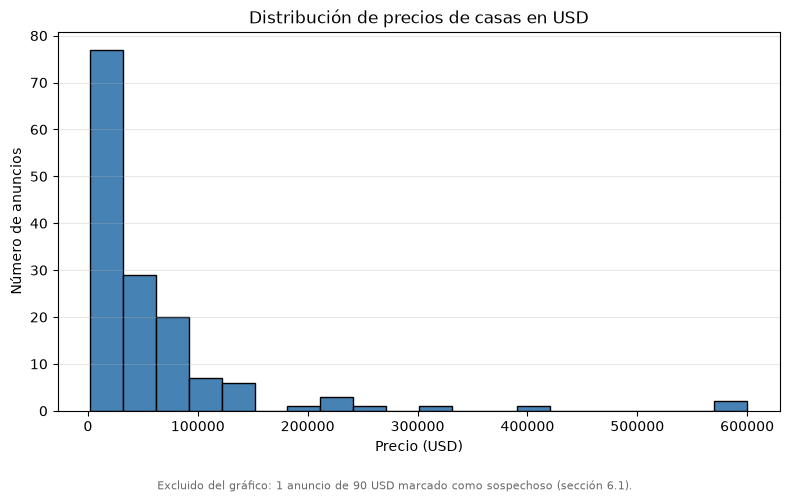

In [20]:
# Histograma de precios (sin el anuncio sospechoso de 90 USD)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(precios_validos, bins=20, edgecolor="black", color="steelblue")
plt.title(f"Distribución de precios de casas en {UNIDAD}")
plt.xlabel(f"Precio ({UNIDAD})")
plt.ylabel("Número de anuncios")
plt.grid(axis="y", alpha=0.3)
plt.figtext(
    0.5, 0.01,
    "Excluido del gráfico: 1 anuncio de 90 USD marcado como sospechoso (sección 6.1).",
    ha="center", fontsize=8, color="dimgray",
)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


### Diagrama de caja (boxplot)

El boxplot muestra la dispersión de los precios, la mediana, los cuartiles y los posibles valores atípicos individuales, en la moneda de análisis. Se excluye el anuncio de 90 USD (posible anomalía, sección 6.1) para que no distorsione la escala; su ficha y la comparación de medianas están en la sección 8.


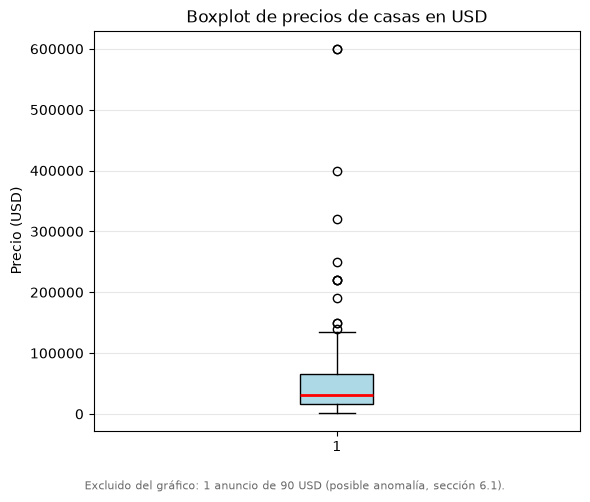

In [21]:
# Diagrama de caja (boxplot) de casas (sin el anuncio sospechoso de 90 USD)
plt.figure(figsize=(6, 5))
plt.boxplot(
    precios_validos,
    orientation="vertical",
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="black"),
    medianprops=dict(color="red", linewidth=2),
)
plt.title(f"Boxplot de precios de casas en {UNIDAD}")
plt.ylabel(f"Precio ({UNIDAD})")
plt.grid(axis="y", alpha=0.3)
plt.figtext(
    0.5, 0.01,
    "Excluido del gráfico: 1 anuncio de 90 USD (posible anomalía, sección 6.1).",
    ha="center", fontsize=8, color="dimgray",
)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


## 8. Análisis de precios extremos

En esta sección revisamos los valores extremos de casas y apartamentos en USD. El objetivo es distinguir un extremo que puede ser legítimo de un valor que probablemente sea un error, sin eliminar ni modificar ningún anuncio. Las fichas muestran solo variables del inmueble: no se reproducen títulos, descripciones ni datos de contacto.


In [22]:
estados_originales = df_casas["precio"]                    # precios originales en USD
estados_originales_validos = df_casas["precio_valido"].dropna()

columnas_ficha = [
    "id_fuente", "fuente", "tipo_inmueble", "municipio", "direccion_texto",
    "area_m2", "habitaciones", "banos", "precio", "moneda", "estado_precio",
]

def mostrar_ficha(registro, etiqueta):
    print(f"--- {etiqueta} ---")
    for col in columnas_ficha:
        valor = registro.get(col)
        if pd.isna(valor):
            valor = "(no disponible)"
        print(f"{col}: {valor}")
    motivo = registro.get("motivo_precio")
    if pd.isna(motivo):
        motivo = "(sin incidencia registrada)"
    print(f"motivo_precio: {motivo}")
    print()

# --- Casas (precios originales en USD) ---
print("=== CASAS CON PRECIO ORIGINAL EN USD ===")
print(f"Precio más bajo observado: {estados_originales.min():,.2f} USD")
print(f"Precio mínimo entre los anuncios no marcados: {estados_originales_validos.min():,.2f} USD")
print(f"Precio máximo: {estados_originales.max():,.2f} USD")
print()

for _, registro in df_casas.loc[df_casas["precio"] == estados_originales.min()].iterrows():
    mostrar_ficha(
        registro,
        f"Precio más bajo observado ({estados_originales.min():,.2f} USD), marcado como posible anomalía",
    )

for _, registro in df_casas.loc[df_casas["precio"] == estados_originales_validos.min()].iterrows():
    mostrar_ficha(
        registro,
        f"Precio mínimo entre los anuncios no marcados ({estados_originales_validos.min():,.2f} USD)",
    )

for _, registro in df_casas.loc[df_casas["precio"] == estados_originales.max()].iterrows():
    mostrar_ficha(registro, f"Precio máximo ({estados_originales.max():,.2f} USD)")

# --- Apartamentos (precios originales en USD) ---
aps = df[
    (df["tipo_inmueble"] == "apartamento") &
    (df["precio"].notna()) &
    (df["moneda"] == "USD")
]
aps_validos = aps["precio_valido"].dropna()

print("=== APARTAMENTOS CON PRECIO ORIGINAL EN USD ===")
print(f"Precio mínimo entre los anuncios no marcados: {aps_validos.min():,.2f} USD")
print(f"Precio máximo: {aps_validos.max():,.2f} USD")
print()

for _, registro in aps.loc[aps["estado_precio"] == "sospechoso"].sort_values("precio").iterrows():
    mostrar_ficha(
        registro,
        f"Precio marcado como inconsistente ({registro['precio']:,.2f} USD), excluido de la distribución",
    )

for _, registro in aps.loc[aps["precio"] == aps_validos.min()].iterrows():
    mostrar_ficha(
        registro,
        f"Precio mínimo entre los anuncios no marcados ({aps_validos.min():,.2f} USD)",
    )

for _, registro in aps.loc[aps["precio"] == aps_validos.max()].iterrows():
    mostrar_ficha(registro, f"Precio máximo ({aps_validos.max():,.2f} USD)")


=== CASAS CON PRECIO ORIGINAL EN USD ===
Precio más bajo observado: 90.00 USD
Precio mínimo entre los anuncios no marcados: 2,300.00 USD
Precio máximo: 600,000.00 USD

--- Precio más bajo observado (90.00 USD), marcado como posible anomalía ---
id_fuente: 0b9d0af4-80cf-4235-b1bf-d4efae9ca009
fuente: gaos
tipo_inmueble: casa
municipio: Diez de Octubre
direccion_texto: Diez de Octubre, La Habana
area_m2: 240.0
habitaciones: 4.0
banos: 4.0
precio: 90.0
moneda: USD
estado_precio: sospechoso
motivo_precio: Posible valor anómalo: 90 USD para una casa de 240 m² con 4 habitaciones y 4 baños. No se afirma cuál sería el precio correcto.

--- Precio mínimo entre los anuncios no marcados (2,300.00 USD) ---
id_fuente: 1192d893-d0ca-42bb-bd7c-69ca05f7a7a9
fuente: gaos
tipo_inmueble: casa
municipio: Arroyo Naranjo
direccion_texto: Arroyo Naranjo, cerca del policlínico de Mantilla
area_m2: (no disponible)
habitaciones: 1.0
banos: 1.0
precio: 2300.0
moneda: USD
estado_precio: ok
motivo_precio: (sin inc

### Observaciones

Esta sección trabaja con los **precios originales en USD**, con independencia de la moneda de visualización elegida en la sección 6.3, porque su objetivo es documentar la calidad de los datos de origen.

**Casa de 90 USD (posible anomalía, no error demostrado).** El valor está almacenado tal como lo publica la fuente y coincide con el campo de precio original. El anuncio no contiene ninguna frase que permita corregirlo y **no se afirma que el precio correcto sea 90 000 USD**. Lo que sí puede afirmarse es que es incompatible con el resto de la ficha (240 m², 4 habitaciones, 4 baños) y con los diez anuncios del conjunto que cumplen las tres condiciones siguientes: superficie declarada entre 150 y 1 000 m² —el rango que la sección 6.2 considera utilizable—, al menos 4 habitaciones y al menos 3 baños. Sus precios se sitúan entre 60 000 y 220 000 USD. Conviene precisar que esa selección se basa en la **superficie declarada**, no en el área construida: `tipo_area` no está identificado en ningún anuncio, así que no puede asegurarse que todas las superficies correspondan al área construida ni que los anuncios sean estrictamente comparables por esa magnitud. Por eso se excluye del mínimo, la media y los gráficos de distribución, pero se mantiene en la mediana: incluyéndolo, la mediana es 30 000 USD; excluyéndolo, 31 000 USD. La diferencia es de un 3,33 %, así que su presencia sí afecta al titular del análisis y debe declararse.

**Precio máximo (600 000 USD).** Es un valor extremo pero coherente con el inmueble: una casa de gran tamaño en Miramar. No hay indicios de error, así que se conserva en todos los cálculos.

**Apartamentos de 5,0 y 5,5 USD.** No son extremos plausibles: la descripción de ambos anuncios indica 5 000 USD. Se conservan los valores originales, se documenta la contradicción y se excluyen de la distribución de precios de apartamentos y de su histograma, donde el mínimo real pasa a ser 1 500 USD.

**Discrepancias menores.** Dos anuncios tienen un precio almacenado algo distinto del que menciona su descripción (65 000 frente a "60 thousand"; 7 000 frente a "8000"). No se corrigen ni se excluyen: la diferencia es pequeña y no altera las conclusiones, pero queda registrada como advertencia.


## 9. Precio de los apartamentos en La Habana

En esta sección respondemos a la segunda pregunta del proyecto: ¿cuánto cuesta un apartamento en La Habana? La base son los **112 apartamentos con precio original en USD**, que forman parte de los 113 apartamentos y de los 307 registros capturados (sección 6.4). Los precios se muestran en la moneda elegida en la sección 6.3.

No se mezclan monedas ni se descartan anuncios del conjunto de datos. El apartamento que no entra en esta base sigue en `df`: no tiene moneda, así que su precio no puede expresarse en USD ni compararse con el resto. Dentro de los 112, los dos anuncios de 5,0 y 5,5 USD marcados como sospechosos en la sección 6.1 se excluyen de la distribución, tal como se documenta allí.

In [23]:
# Filtrar anuncios: tipo_inmueble == 'apartamento' y precio disponible en la moneda de análisis
df_apartamentos = df[
    (df["tipo_inmueble"] == "apartamento") &
    (df["precio_analisis"].notna())
].copy()

marcados = df_apartamentos[df_apartamentos["estado_precio"] == "sospechoso"]

print(f"Anuncios totales (registros capturados): {len(df)}")
print(f"Apartamentos en el conjunto: {int((df['tipo_inmueble'] == 'apartamento').sum())}")
print(f"Apartamentos con precio original en USD: {len(df_apartamentos)}")
print(f"Moneda de análisis: {UNIDAD}")
print(f"Porcentaje sobre los {len(df)} registros capturados: {len(df_apartamentos) / len(df) * 100:.2f}%")
print()
print(f"Excluidos de las estadísticas de distribución: {len(marcados)}")
for _, registro in marcados.iterrows():
    print(f"  - {registro['id_fuente']}: {registro['precio']:,.1f} USD (original) | {registro['motivo_precio']}")
print(f"Anuncios usados en la distribución: {len(df_apartamentos) - len(marcados)}")

Anuncios totales (registros capturados): 307
Apartamentos en el conjunto: 113
Apartamentos con precio original en USD: 112
Moneda de análisis: USD
Porcentaje sobre los 307 registros capturados: 36.48%

Excluidos de las estadísticas de distribución: 2
  - 1cd0b62f-030a-4fa2-9e9e-0fd08739715b: 5.0 USD (original) | Precio numérico de 5,0 USD que contradice la descripción del anuncio, donde se indica 5 000 USD.
  - 6e42ec20-0de9-439a-a639-96152346655a: 5.5 USD (original) | Precio numérico de 5,5 USD que contradice la descripción del anuncio, donde se indica 5 000 USD.
Anuncios usados en la distribución: 110


In [24]:
# Estadísticas descriptivas del precio (sin los anuncios con precio inconsistente)
precios_ap = df_apartamentos["precio_analisis_valido"].dropna()
precios_ap_todos = df_apartamentos["precio_analisis"]

print(f"Base: {len(precios_ap_todos)} apartamentos con precio original en USD")
print(f"Anuncios usados en las estadísticas de distribución: {len(precios_ap)}")
print(f"Media: {precios_ap.mean():,.2f} {UNIDAD}")
print(f"Mediana: {precios_ap.median():,.2f} {UNIDAD}")
print(f"Mínimo: {precios_ap.min():,.2f} {UNIDAD}")
print(f"Máximo: {precios_ap.max():,.2f} {UNIDAD}")
print(f"Primer cuartil (Q1, 25%): {precios_ap.quantile(0.25):,.2f} {UNIDAD}")
print(f"Tercer cuartil (Q3, 75%): {precios_ap.quantile(0.75):,.2f} {UNIDAD}")
print()
print("--- Efecto de los dos anuncios excluidos ---")
print(
    f"Con los {len(precios_ap_todos)} anuncios: "
    f"media {precios_ap_todos.mean():,.2f} {UNIDAD}, mediana {precios_ap_todos.median():,.2f} {UNIDAD}"
)
print(
    f"Sin los 2 anuncios: "
    f"media {precios_ap.mean():,.2f} {UNIDAD}, mediana {precios_ap.median():,.2f} {UNIDAD}"
)

Base: 112 apartamentos con precio original en USD
Anuncios usados en las estadísticas de distribución: 110
Media: 26,922.73 USD
Mediana: 15,000.00 USD
Mínimo: 1,500.00 USD
Máximo: 180,000.00 USD
Primer cuartil (Q1, 25%): 8,625.00 USD
Tercer cuartil (Q3, 75%): 28,750.00 USD

--- Efecto de los dos anuncios excluidos ---
Con los 112 anuncios: media 26,442.06 USD, mediana 15,000.00 USD
Sin los 2 anuncios: media 26,922.73 USD, mediana 15,000.00 USD


In [25]:
# Tabla resumen de estadísticas
tabla_estadisticas_ap = pd.DataFrame({
    "estadístico": [
        "Cantidad total de apartamentos con precio original en USD",
        "Anuncios excluidos de la distribución",
        "Cantidad usada",
        "Media",
        "Mediana",
        "Mínimo",
        "Máximo",
        "Q1 (25%)",
        "Q3 (75%)",
    ],
    f"valor ({UNIDAD})": [
        f"{len(precios_ap_todos)}",
        f"{len(precios_ap_todos) - len(precios_ap)}",
        f"{len(precios_ap)}",
        f"{precios_ap.mean():,.2f}",
        f"{precios_ap.median():,.2f}",
        f"{precios_ap.min():,.2f}",
        f"{precios_ap.max():,.2f}",
        f"{precios_ap.quantile(0.25):,.2f}",
        f"{precios_ap.quantile(0.75):,.2f}",
    ],
})

print(tabla_estadisticas_ap.to_string(index=False))


                                              estadístico valor (USD)
Cantidad total de apartamentos con precio original en USD         112
                    Anuncios excluidos de la distribución           2
                                           Cantidad usada         110
                                                    Media   26,922.73
                                                  Mediana   15,000.00
                                                   Mínimo    1,500.00
                                                   Máximo  180,000.00
                                                 Q1 (25%)    8,625.00
                                                 Q3 (75%)   28,750.00


### Histograma de precios

El histograma muestra cuántos anuncios hay en cada rango de precios, permitiendo observar la distribución y detectar concentraciones de precios. Se representan los anuncios usados en la distribución (sin los dos precios inconsistentes) y el eje está expresado en la moneda de análisis.


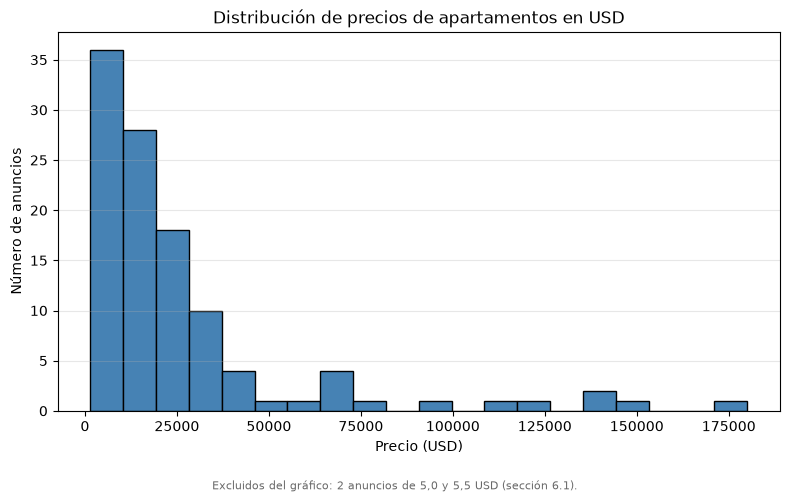

In [26]:
# Histograma de precios de apartamentos (sin los 2 anuncios con precio inconsistente)
plt.figure(figsize=(8, 5))
plt.hist(precios_ap, bins=20, edgecolor="black", color="steelblue")
plt.title(f"Distribución de precios de apartamentos en {UNIDAD}")
plt.xlabel(f"Precio ({UNIDAD})")
plt.ylabel("Número de anuncios")
plt.grid(axis="y", alpha=0.3)
plt.figtext(
    0.5, 0.01,
    "Excluidos del gráfico: 2 anuncios de 5,0 y 5,5 USD (sección 6.1).",
    ha="center", fontsize=8, color="dimgray",
)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


### Diagrama de caja (boxplot)

El boxplot muestra la dispersión de los precios, la mediana, los cuartiles y los posibles valores atípicos individuales, en la moneda de análisis.


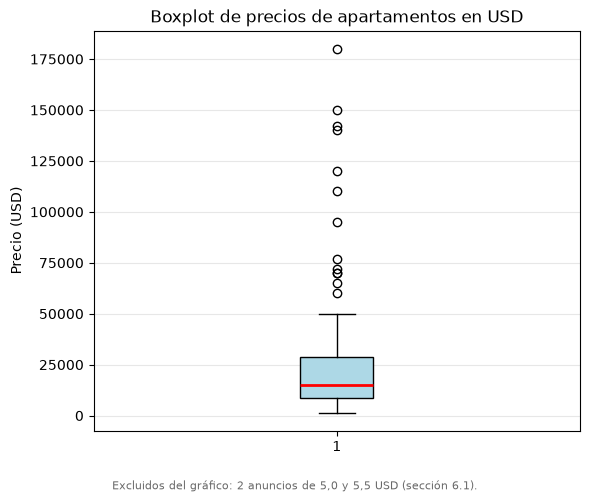

In [27]:
# Diagrama de caja (boxplot) de apartamentos (sin los 2 anuncios con precio inconsistente)
plt.figure(figsize=(6, 5))
plt.boxplot(
    precios_ap,
    orientation="vertical",
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="black"),
    medianprops=dict(color="red", linewidth=2),
)
plt.title(f"Boxplot de precios de apartamentos en {UNIDAD}")
plt.ylabel(f"Precio ({UNIDAD})")
plt.grid(axis="y", alpha=0.3)
plt.figtext(
    0.5, 0.01,
    "Excluidos del gráfico: 2 anuncios de 5,0 y 5,5 USD (sección 6.1).",
    ha="center", fontsize=8, color="dimgray",
)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


### Interpretación

Las estadísticas y los gráficos se calculan sobre los anuncios de apartamento con precio original en USD que no están marcados como inconsistentes. La media es notablemente superior a la mediana, lo que indica una distribución asimétrica: unos pocos anuncios con precios altos elevan el promedio, mientras la mayoría se concentra en valores menores.

Excluir los dos anuncios de 5,0 y 5,5 USD no cambia la mediana y eleva ligeramente la media. Su efecto era reducir artificialmente el promedio y, sobre todo, fijar un mínimo de 5 USD que no corresponde a ninguna vivienda; el mínimo de la muestra pasa a ser el del anuncio más barato no marcado.


## 10. Distribución de precios por municipio

Antes de comparar precios entre municipios, evaluamos si los datos permiten realizar este análisis de manera razonable. Revisamos cuántos anuncios tienen municipio identificado, cómo se distribuyen por municipio y cuántos tienen precio disponible en la moneda de análisis.


### 10.1. Cobertura municipal

Antes de comparar precios se mide cuántos registros tienen municipio identificado. Los porcentajes de esta subsección se calculan sobre los 307 registros capturados. Los registros sin municipio permanecen en el conjunto de datos: no se les asigna una ubicación ni se reparten entre municipios.

In [28]:
# Cobertura de municipio: total y desglose por tipo de inmueble
total = len(df)
con_mun = df[df["municipio"].notna()]
sin_mun = df[df["municipio"].isna()]

print(f"Total de anuncios capturados: {total}")
print(f"Con municipio identificado: {len(con_mun)} ({len(con_mun) / total * 100:.2f}% de {total})")
print(f"Sin municipio: {len(sin_mun)} ({len(sin_mun) / total * 100:.2f}% de {total})")
print()

print("Por tipo de inmueble (con municipio / sin municipio):")
for etiqueta, tipo in [
    ("Casas", "casa"),
    ("Apartamentos", "apartamento"),
    ("Tipo indeterminado", "indeterminado"),
    ("No corresponde a vivienda", "no_vivienda"),
]:
    sub = df[df["tipo_inmueble"] == tipo]
    print(f"  {etiqueta}: {int(sub['municipio'].notna().sum())} / {int(sub['municipio'].isna().sum())}")
sub = df[df["tipo_inmueble"].isna()]
print(f"  Sin tipo: {int(sub['municipio'].notna().sum())} / {int(sub['municipio'].isna().sum())}")

# Base de las tablas de precios: solo casa o apartamento con municipio.
base_municipal = df[
    df["tipo_inmueble"].isin(["casa", "apartamento"]) & df["municipio"].notna()
]
con_precio_mun = base_municipal[base_municipal["precio_analisis_valido"].notna()]
marcados_mun = base_municipal[base_municipal["estado_precio"] == "sospechoso"]
sin_precio_mun = base_municipal[
    (base_municipal["estado_precio"] != "sospechoso")
    & base_municipal["precio_analisis"].isna()
]
otros_mun = con_mun[~con_mun["tipo_inmueble"].isin(["casa", "apartamento"])]

print()
print(f"Registros con municipio clasificados como casa o apartamento: {len(base_municipal)}")
print(f"  - con precio válido en USD para las estadísticas: {len(con_precio_mun)}")
print(f"  - excluidos por precio marcado en la sección 6.1: {len(marcados_mun)}")
print(f"  - excluidos por no tener precio utilizable: {len(sin_precio_mun)}")
print()
print(f"Otros registros con municipio no clasificados como casa o apartamento: {len(otros_mun)}")
print(otros_mun["tipo_inmueble"].fillna("(sin tipo)").value_counts().to_string())

Total de anuncios capturados: 307
Con municipio identificado: 187 (60.91% de 307)
Sin municipio: 120 (39.09% de 307)

Por tipo de inmueble (con municipio / sin municipio):
  Casas: 103 / 51
  Apartamentos: 80 / 33
  Tipo indeterminado: 3 / 33
  No corresponde a vivienda: 0 / 3
  Sin tipo: 1 / 0

Registros con municipio clasificados como casa o apartamento: 183
  - con precio válido en USD para las estadísticas: 176
  - excluidos por precio marcado en la sección 6.1: 3
  - excluidos por no tener precio utilizable: 4

Otros registros con municipio no clasificados como casa o apartamento: 4
tipo_inmueble
indeterminado    3
(sin tipo)       1


### 10.2. Anuncios por municipio y tipo

La tabla cuenta los 187 registros con municipio y usa ese total como denominador de los porcentajes. Casas, apartamentos y registros no clasificados como casa o apartamento se muestran en columnas separadas. Los 120 registros sin municipio no forman parte de la tabla.

In [29]:
# Distribución de los registros con municipio, separando casas y apartamentos
municipios_df = df[df["municipio"].notna()].copy()


def clasificar_tipo(tipo):
    if pd.isna(tipo):
        return "Sin tipo"
    if tipo == "casa":
        return "Casa"
    if tipo == "apartamento":
        return "Apartamento"
    if tipo == "indeterminado":
        return "Indeterminado"
    return "No corresponde a vivienda"


municipios_df["tipo_cat"] = municipios_df["tipo_inmueble"].apply(clasificar_tipo)

dist = municipios_df.groupby(["municipio", "tipo_cat"]).size().unstack(fill_value=0)
orden = ["Casa", "Apartamento", "Indeterminado", "Sin tipo"]
for columna in orden:
    if columna not in dist.columns:
        dist[columna] = 0
dist = dist[orden]
dist["Total"] = dist.sum(axis=1)
dist["% de 187"] = (dist["Total"] / len(municipios_df) * 100).round(2)
dist = dist.sort_values("Total", ascending=False).reset_index()

print(dist.to_string(index=False))
print("(los porcentajes pueden no sumar 100 exactos por redondeo)")
print()
print(f"Total con municipio: {len(municipios_df)} registros "
      f"({len(municipios_df) / total * 100:.2f}% de {total})")
print(f"Sin municipio: {len(sin_mun)} registros "
      f"({len(sin_mun) / total * 100:.2f}% de {total})")
print()
print(
    f"Otros registros no clasificados como casa o apartamento: "
    f"{int(dist['Indeterminado'].sum())} de tipo indeterminado y "
    f"{int(dist['Sin tipo'].sum())} sin tipo"
)
print("Los 3 registros que no corresponden a vivienda no tienen municipio")
print("y no aparecen en la tabla. Los registros sin municipio siguen en el conjunto.")

             municipio  Casa  Apartamento  Indeterminado  Sin tipo  Total  % de 187
Plaza de la Revolución    12           22              0         0     34     18.18
                 Playa    17            7              0         0     24     12.83
         Centro Habana     4           12              1         0     17      9.09
    La Habana del Este    12            5              0         0     17      9.09
               La Lisa     5            8              0         0     13      6.95
              Marianao     7            4              1         1     13      6.95
               Boyeros     9            2              1         0     12      6.42
        Arroyo Naranjo     8            2              0         0     10      5.35
       Diez de Octubre     7            3              0         0     10      5.35
                 Cerro     2            6              0         0      8      4.28
          Habana Vieja     3            5              0         0      8   

### 10.3. Precios por municipio y tipo

Cada tabla incluye solo registros de su tipo con municipio y precio válido en la moneda de análisis. La columna `n` indica cuántos anuncios sustentan cada fila; los municipios con `n < 5` llevan la marca «insuficiente (n<5)» y no se interpretan. La fila «Sin municipio» es una referencia: no es un municipio y no se suma a los totales municipales.

In [30]:
# Precios por municipio y tipo (solo casas o apartamentos con precio válido)


def resumen_precios(serie):
    """n, mediana, media y cuartiles de una serie de precios válidos."""
    return {
        "n": int(serie.count()),
        "mediana": serie.median(),
        "media": serie.mean(),
        "p25": serie.quantile(0.25),
        "p75": serie.quantile(0.75),
    }


def tabla_por_municipio(tipo):
    sub = df[
        (df["tipo_inmueble"] == tipo)
        & df["municipio"].notna()
        & df["precio_analisis_valido"].notna()
    ]
    filas = [
        {"municipio": municipio, **resumen_precios(grupo["precio_analisis_valido"])}
        for municipio, grupo in sub.groupby("municipio")
    ]
    tabla = pd.DataFrame(filas).sort_values("n", ascending=False).reset_index(drop=True)
    tabla["marca"] = ["insuficiente (n<5)" if n < 5 else "" for n in tabla["n"]]
    return tabla


def mostrar_precios(tabla):
    vista = tabla.copy()
    for columna in ("mediana", "media", "p25", "p75"):
        vista[columna] = vista[columna].map(lambda v: f"{v:,.2f}")
    print(vista.to_string(index=False))


for tipo, etiqueta in [("casa", "CASAS"), ("apartamento", "APARTAMENTOS")]:
    tabla = tabla_por_municipio(tipo)
    print(f"=== {etiqueta}: precios por municipio ===")
    mostrar_precios(tabla)
    print(f"Total de municipios: {int(tabla['n'].sum())} anuncios")
    print()

    referencia = df[
        (df["tipo_inmueble"] == tipo)
        & df["municipio"].isna()
        & df["precio_analisis_valido"].notna()
    ]["precio_analisis_valido"]
    print("Sin municipio (referencia; no es un municipio y no se suma al total anterior):")
    mostrar_precios(pd.DataFrame([{"municipio": "Sin municipio", **resumen_precios(referencia)}]))
    print()

print(f"Precios en {UNIDAD}. Solo se incluyen registros clasificados como casa o apartamento.")
print()
print("Reconciliación de los registros con municipio clasificados como casa o apartamento:")
print(f"  {len(base_municipal)} = {len(con_precio_mun)} con precio válido "
      f"+ {len(marcados_mun)} marcados + {len(sin_precio_mun)} sin precio utilizable")
print("  Los marcados son los 3 anuncios de la sección 6.1; los otros 4 son")
print("  3 casas en EUR y 1 casa en USD sin precio.")
print()
print("Los municipios con la marca «insuficiente (n<5)» se muestran pero no se")
print("interpretan; su conteo sí forma parte del total de municipios.")

=== CASAS: precios por municipio ===
             municipio  n   mediana      media       p25        p75              marca
                 Playa 17 70,000.00 127,588.24 45,000.00 120,000.00                   
Plaza de la Revolución 12 61,500.00 105,812.50 40,000.00 167,500.00                   
    La Habana del Este 10 67,500.00  76,900.00 51,250.00 107,500.00                   
               Boyeros  9 80,000.00  68,000.00 65,000.00  80,000.00                   
              Marianao  7 17,000.00  22,857.14 15,500.00  27,500.00                   
        Arroyo Naranjo  7  5,000.00  11,971.43  4,500.00  18,750.00                   
       Diez de Octubre  6 16,500.00  22,833.33  9,250.00  26,750.00                   
 San Miguel del Padrón  6  6,250.00  10,250.00  4,750.00  13,000.00                   
               La Lisa  5 30,000.00  34,000.00 25,000.00  30,000.00                   
            Guanabacoa  4 42,500.00  40,250.00 34,000.00  48,750.00 insuficiente (n<5)
      

=== APARTAMENTOS: precios por municipio ===
             municipio  n   mediana     media       p25        p75              marca
Plaza de la Revolución 22 35,000.00 47,840.91 23,000.00  62,000.00                   
         Centro Habana 12 13,000.00 12,958.33  8,375.00  14,500.00                   
               La Lisa  8  8,000.00 11,125.00  6,125.00  12,500.00                   
                 Playa  7 24,000.00 72,000.00 21,500.00 122,500.00                   
          Habana Vieja  5 15,000.00 21,200.00  9,500.00  35,000.00                   
    La Habana del Este  5 18,500.00 16,800.00 14,000.00  18,500.00                   
                 Cerro  4 12,000.00 13,125.00  8,125.00  17,000.00 insuficiente (n<5)
              Marianao  4  9,500.00 20,875.00  4,875.00  25,500.00 insuficiente (n<5)
       Diez de Octubre  3 12,000.00 12,333.33 11,000.00  13,500.00 insuficiente (n<5)
        Arroyo Naranjo  2 13,000.00 13,000.00 10,500.00  15,500.00 insuficiente (n<5)
          

### 10.4. Valoración metodológica

- **¿Qué proporción del conjunto tiene municipio identificado?** 187 de los 307 registros capturados (60,91 %); 120 (39,09 %) no lo tienen. La cobertura depende del tipo: 103 de las 154 casas (66,88 %) y 80 de los 113 apartamentos (70,80 %).
- **¿Cuántos registros entran en las tablas de precios?** 176 de los 183 registros con municipio clasificados como casa o apartamento: 98 casas y 78 apartamentos. Quedan fuera 7: 3 marcados en la sección 6.1 y 4 sin precio utilizable (3 casas en EUR y 1 casa en USD sin precio). Los otros 4 registros con municipio (3 de tipo indeterminado y 1 sin tipo) no están clasificados como casa ni apartamento y no se incluyen en las tablas de precios; no se afirma que no sean viviendas.
- **¿Hay municipios con muy pocos anuncios?** Sí. Con el umbral de n<5, en casas quedan marcados 6 municipios (Cerro 2, Habana Vieja 3, Cotorro 3, Regla 3, Centro Habana 4 y Guanabacoa 4), que reúnen 19 de las 98 casas. En apartamentos se marcan 8 municipios (Cotorro 1, San Miguel del Padrón 1, Arroyo Naranjo 2, Boyeros 2, Guanabacoa 2, Diez de Octubre 3, Cerro 4 y Marianao 4), con 19 de los 78 apartamentos. Regla no tiene apartamentos.
- **¿Qué pasa con los registros sin municipio?** Permanecen en el conjunto de datos y no se les asigna una ubicación. En las tablas de precios aparecen solo como fila de referencia (50 casas y 32 apartamentos), separada de los municipios y sin sumarse a sus totales.
- **¿Por qué separar casas y apartamentos?** Porque la composición por tipo cambia mucho entre municipios y la mediana conjunta queda dominada por el tipo más numeroso. Por ejemplo, en Plaza de la Revolución la mediana conjunta era 37.375 USD, frente a 61.500 en casas y 35.000 en apartamentos; en Playa, 69.000 frente a 70.000 y 24.000. Incluir registros no clasificados también alteraba cifras: en Boyeros, la mediana conjunta de la tabla anterior pasaba de 72.500 a 65.000 al retirar el anuncio de tipo indeterminado de 80.000 USD.
- **¿La cobertura municipal depende principalmente de GAOS o de Revolico?** De GAOS: identifica municipio en el 81,5 % de sus anuncios, frente al 22,4 % de Revolico.
- **¿Qué limitaciones quedan?** La cobertura es desigual (39,09 % sin municipio), los municipios con n<5 no se interpretan y, entre los que no llevan esa marca, varios tienen entre 5 y 9 anuncios por tipo, de modo que sus medianas deben leerse con cautela. A esto se suma que son precios anunciados, no de transacción.

**Conclusión metodológica:** las comparaciones entre municipios solo tienen sentido dentro de cada tipo de inmueble y para los municipios sin marca de insuficiencia; aun así, el tamaño de las muestras y la cobertura desigual obligan a presentarlas como exploratorias.

## 11. Composición municipal por tipo de inmueble

Examinamos cómo se distribuyen los tipos de inmueble dentro de cada municipio. Esto nos permite interpretar mejor las diferencias de precios observadas en la sección anterior, ya que un municipio con predominio de casas no es directamente comparable a uno con predominio de apartamentos.

### 11.1. Composición por municipio y tipo

Esta tabla es descriptiva y no contiene estadísticas de precio: cuenta los 307 registros capturados por municipio y tipo, incluidos los que no tienen precio utilizable. La fila «Sin municipio» se muestra separada y reúne los registros sin ubicación.

In [31]:
# Composición de los registros por municipio y tipo (descriptiva: incluye todos los tipos)
mapa_tipo = {
    "casa": "Casa",
    "apartamento": "Apartamento",
    "indeterminado": "Indeterminado",
    "no_vivienda": "No vivienda",
}
conteo = df.assign(
    municipio=df["municipio"].fillna("Sin municipio"),
    tipo_cat=df["tipo_inmueble"].map(mapa_tipo).fillna("Sin tipo"),
)

tabla_tipo = conteo.groupby(["municipio", "tipo_cat"]).size().unstack(fill_value=0)
orden = ["Casa", "Apartamento", "Indeterminado", "Sin tipo", "No vivienda"]
for columna in orden:
    if columna not in tabla_tipo.columns:
        tabla_tipo[columna] = 0
tabla_tipo = tabla_tipo[orden]
tabla_tipo["Total"] = tabla_tipo.sum(axis=1)

municipios = tabla_tipo.drop(index="Sin municipio").sort_values("Total", ascending=False)
sin_municipio = tabla_tipo.loc[["Sin municipio"]]
total_fila = tabla_tipo.sum().to_frame().T
total_fila.index = ["Total"]

tabla_final = pd.concat([municipios, sin_municipio, total_fila])
print(tabla_final.to_string())
print()
print("La columna «No vivienda» corresponde a los 3 registros que no son viviendas.")
print()
print("La fila «Sin municipio» agrupa los registros sin ubicación; no es un municipio")
print(f"y se muestra separada para que el total cuadre con los {len(df)} registros capturados.")

tipo_cat                Casa  Apartamento  Indeterminado  Sin tipo  No vivienda  Total
Plaza de la Revolución    12           22              0         0            0     34
Playa                     17            7              0         0            0     24
Centro Habana              4           12              1         0            0     17
La Habana del Este        12            5              0         0            0     17
La Lisa                    5            8              0         0            0     13
Marianao                   7            4              1         1            0     13
Boyeros                    9            2              1         0            0     12
Arroyo Naranjo             8            2              0         0            0     10
Diez de Octubre            7            3              0         0            0     10
Cerro                      2            6              0         0            0      8
Habana Vieja               3            5  

### 11.2. Valoración metodológica

- **¿Los municipios tienen una composición similar de casas y apartamentos?** No. Playa tiene 17 casas frente a 7 apartamentos y Boyeros 9 frente a 2, mientras que Plaza de la Revolución tiene 22 apartamentos frente a 12 casas y Centro Habana 12 apartamentos frente a 4 casas. Regla solo tiene casas (3) y ningún apartamento.
- **¿Qué implica esto para la comparación de precios?** Que los precios de casas y apartamentos no son directamente comparables entre municipios si la composición de tipos es muy diferente; por eso la sección 10 presenta las estadísticas separadas por tipo.
- **¿Qué son los registros «no clasificados como casa o apartamento»?** Los 4 registros con municipio que no están clasificados como casa ni apartamento: 3 de tipo indeterminado (Centro Habana, Marianao y Boyeros) y 1 sin tipo (Marianao). No se puede confirmar que sean viviendas, pero tampoco que no lo sean; por eso no entran en las tablas de precios y sí en esta tabla de composición.
- **¿Y los registros sin municipio?** Son 120 (51 casas, 33 apartamentos, 33 de tipo indeterminado y 3 que no corresponden a vivienda). Se muestran como fila separada al final de la tabla, permanecen en el conjunto y no se les asigna ubicación.
- **Limitación adicional:** muchos municipios tienen muy pocos anuncios cuando se separan por tipo de inmueble (por ejemplo, 1 apartamento en San Miguel del Padrón o en Cotorro), lo que hace que sus recuentos no sean representativos. En esta sección los recuentos incluyen todos los registros con municipio (187), no solo los que tienen precio válido en USD (176); son bases distintas y no deben mezclarse.

## 12. Características de las viviendas por precio relativo a la mediana

En esta sección respondemos a la pregunta: ¿qué características aparecen con mayor frecuencia en los anuncios cuyo precio supera la mediana? Para ello, filtramos los anuncios clasificados como `casa` o `apartamento` con precio registrado y expresado originalmente en USD. Los precios se manejan en la moneda elegida en la sección 6.3; como la conversión es un factor constante, los grupos por encima y por debajo de la mediana son los mismos en USD y en CUP.

Separamos los anuncios de casas y de apartamentos en dos grupos: aquellos con precio superior a la mediana y aquellos con precio igual o inferior. Luego comparamos la distribución de habitaciones y baños entre ambos grupos.

**Nota:** Los porcentajes se calculan solo sobre los anuncios que tienen dato para cada característica, no sobre el total del grupo.

**Nota sobre los anuncios marcados en la sección 6.1:** se mantienen en esta sección porque aquí no se calculan estadísticas descriptivas de precio: solo se usa la mediana como punto de corte y se cuentan características. Su exclusión afecta únicamente a las estadísticas de precio de las secciones 7, 9 y 10.


In [32]:
# Población y medianas en la moneda de análisis
mediana_casas = df_casas["precio_analisis"].median()
mediana_apartamentos = df_apartamentos["precio_analisis"].median()

print(f'Casas: {len(df_casas)}')
print(f'Mediana de casas: {mediana_casas:,.2f} {UNIDAD}')
print()
print(f'Apartamentos: {len(df_apartamentos)}')
print(f'Mediana de apartamentos: {mediana_apartamentos:,.2f} {UNIDAD}')


Casas: 149
Mediana de casas: 30,000.00 USD

Apartamentos: 112
Mediana de apartamentos: 15,000.00 USD


In [33]:
# Separar en grupos por encima e igual o inferior a la mediana
casas_arriba = df_casas[df_casas["precio_analisis"] > mediana_casas].copy()
casas_abajo = df_casas[df_casas["precio_analisis"] <= mediana_casas].copy()

apartamentos_arriba = df_apartamentos[df_apartamentos["precio_analisis"] > mediana_apartamentos].copy()
apartamentos_abajo = df_apartamentos[df_apartamentos["precio_analisis"] <= mediana_apartamentos].copy()

print(f'Casas arriba de la mediana: {len(casas_arriba)}')
print(f'Casas igual o inferior a la mediana: {len(casas_abajo)}')
print()
print(f'Apartamentos arriba de la mediana: {len(apartamentos_arriba)}')
print(f'Apartamentos igual o inferior a la mediana: {len(apartamentos_abajo)}')


Casas arriba de la mediana: 74
Casas igual o inferior a la mediana: 75

Apartamentos arriba de la mediana: 54
Apartamentos igual o inferior a la mediana: 58


In [34]:
# Tablas de distribución de habitaciones y baños por grupo

def tabla_distribucion(grupo, nombre_grupo):
    print(f'\n--- {nombre_grupo} ---')
    print(f'Total anuncios: {len(grupo)}')
    print(f'Con dato de habitaciones: {grupo["habitaciones"].notna().sum()}')
    print(f'Sin dato de habitaciones: {grupo["habitaciones"].isna().sum()}')
    print(f'Con dato de baños: {grupo["banos"].notna().sum()}')
    print(f'Sin dato de baños: {grupo["banos"].isna().sum()}')
    print()
    print('Distribución de habitaciones:')
    hab = grupo['habitaciones'].value_counts().sort_index()
    n_hab = grupo['habitaciones'].notna().sum()
    for v, c in hab.items():
        print(f'  {int(v)}: {c} ({c/n_hab*100:.1f}%)')
    print()
    print('Distribución de baños:')
    ban = grupo['banos'].value_counts().sort_index()
    n_ban = grupo['banos'].notna().sum()
    for v, c in ban.items():
        print(f'  {int(v)}: {c} ({c/n_ban*100:.1f}%)')
    print()

tabla_distribucion(casas_arriba, 'CASAS ARRIBA DE LA MEDIANA')
tabla_distribucion(casas_abajo, 'CASAS ABAJO O IGUAL A LA MEDIANA')
tabla_distribucion(apartamentos_arriba, 'APARTAMENTOS ARRIBA DE LA MEDIANA')
tabla_distribucion(apartamentos_abajo, 'APARTAMENTOS ABAJO O IGUAL A LA MEDIANA')


--- CASAS ARRIBA DE LA MEDIANA ---
Total anuncios: 74
Con dato de habitaciones: 48
Sin dato de habitaciones: 26
Con dato de baños: 48
Sin dato de baños: 26

Distribución de habitaciones:
  2: 8 (16.7%)
  3: 13 (27.1%)
  4: 12 (25.0%)
  5: 7 (14.6%)
  6: 4 (8.3%)
  7: 2 (4.2%)
  8: 1 (2.1%)
  10: 1 (2.1%)

Distribución de baños:
  1: 11 (22.9%)
  2: 15 (31.2%)
  3: 15 (31.2%)
  4: 1 (2.1%)
  6: 2 (4.2%)
  7: 3 (6.2%)
  8: 1 (2.1%)


--- CASAS ABAJO O IGUAL A LA MEDIANA ---
Total anuncios: 75
Con dato de habitaciones: 55
Sin dato de habitaciones: 20
Con dato de baños: 51
Sin dato de baños: 24

Distribución de habitaciones:
  1: 8 (14.5%)
  2: 20 (36.4%)
  3: 18 (32.7%)
  4: 7 (12.7%)
  5: 2 (3.6%)

Distribución de baños:
  1: 32 (62.7%)
  2: 14 (27.5%)
  3: 3 (5.9%)
  4: 1 (2.0%)
  5: 1 (2.0%)


--- APARTAMENTOS ARRIBA DE LA MEDIANA ---
Total anuncios: 54
Con dato de habitaciones: 40
Sin dato de habitaciones: 14
Con dato de baños: 40
Sin dato de baños: 14

Distribución de habitaciones:


### Interpretación

Las tablas anteriores muestran cómo se distribuyen las características de habitaciones y baños entre los anuncios cuyos precios están por encima y por debajo (o igual) a la mediana, separados por tipo de inmueble y expresados en la moneda de análisis.

En las **casas**, los anuncios por encima de la mediana tienden a tener más habitaciones y más baños que los anuncios por debajo de la mediana. Sin embargo, una proporción considerable de anuncios no informa estas características (el 31 % no informa habitaciones y el 34 % no informa baños), por lo que estos resultados deben interpretarse con cautela.

En los **apartamentos**, también se observa que los anuncios por encima de la mediana tienden a tener más habitaciones y baños que los anuncios por debajo de la mediana, aunque una proporción considerable de anuncios no informa estas características (el 21 % no informa habitaciones y el 26 % no informa baños).

Estos resultados son descriptivos y no implican una relación de causalidad: tener más habitaciones o baños no implica necesariamente un precio más alto, ya que otros factores no disponibles en los datos (ubicación exacta, estado de conservación, acabados, etc.) también influyen en el precio.

Además, varias categorías tienen muy pocos anuncios (por ejemplo, casas con 7, 8 o 10 habitaciones, o apartamentos con 4 o 5 habitaciones), por lo que no se deben sacar conclusiones firmes basadas en esos casos aislados.


## 13. Inmueble representativo y comparación con el salario mínimo legal

En esta sección respondemos a la pregunta: ¿cuál es el inmueble más representativo de los anuncios analizados y cómo se compara su precio con el salario mínimo legal?

Se analizan casas y apartamentos por separado. **Esta sección trabaja siempre con los precios originales en USD**, con independencia de la moneda elegida en la sección 6.3, porque la comparación salarial aplica por separado las dos tasas de cambio. No se combina información de casas y apartamentos.

**Salario de referencia.** Se usa el **salario mínimo legal de 3.210 CUP mensuales**, establecido por la **Resolución 14/2026** (Gaceta Oficial Ordinaria n.º 60 de 2026), vigente desde el **1 de julio de 2026**. No es un salario promedio ni un ingreso representativo de todos los cubanos: es el piso legal de ingresos. El proyecto no dispone de una fuente documentada de salario medio nacional, por lo que no se calcula esa comparación.

**Sobre la escala salarial.** La **Resolución 15/2026** establece la escala del sector presupuestado. Para el **Grupo I**, fija 3.210 CUP con 44 horas semanales y **2.920 CUP con 40 horas**. El valor de 2.920 CUP **no es el salario mínimo** y no se usa en este análisis; se menciona solo para evitar confusiones entre el mínimo legal y la escala.

### 13.1. Características más frecuentes de los inmuebles

Se identifican, por separado para casas y apartamentos: el tipo de inmueble más frecuente, la cantidad de habitaciones más frecuente, la cantidad de baños más frecuente y la mediana del precio.

**Medianas.** La mediana de referencia para la comparación salarial es la de los anuncios válidos: 31.000 USD en casas (148 anuncios, sin la posible anomalía de 90 USD) y 15.000 USD en apartamentos (110 anuncios). La mediana de las 149 casas, 30.000 USD, se conserva como escenario de sensibilidad en la subsección 13.3.

**Nota:** Las frecuencias de habitaciones y baños se calculan solo sobre los anuncios que informan ese dato. Además de las modas individuales, la tabla siguiente muestra la **combinación conjunta de habitaciones y baños** de las casas. Se calcula sobre **99 de las 149 casas con precio en USD**, que son las que informan ambos datos, y **no excluye** registros con incidencias que afecten únicamente al precio, porque esas incidencias no invalidan las características del inmueble. La combinación más frecuente no representa a la mayoría de la muestra.

In [35]:
from collections import Counter

# Población de análisis en USD originales (independiente de la moneda de visualización)
casas_usd = df_casas
apartamentos_usd = df_apartamentos

def moda_con_dato(grupo, clave):
    """Devuelve (valor_moda, conteo_moda, n_con_dato, n_total, n_sin_dato)."""
    serie = grupo[clave].dropna()
    if serie.empty:
        return None, 0, 0, len(grupo), len(grupo)
    conteo = Counter(serie)
    modas = sorted(conteo.items(), key=lambda item: (-item[1], item[0]))
    return modas[0][0], modas[0][1], len(serie), len(grupo), len(grupo) - len(serie)

# Casas: mediana con todos los anuncios y sin la posible anomalía
precios_casas_usd = casas_usd["precio"]
mediana_casas_usd = precios_casas_usd.median()
mediana_casas_sin_anomalia_usd = casas_usd["precio_valido"].dropna().median()
hab_casa, n_hab_casa, disp_hab_casa, tot_casa, sin_hab_casa = moda_con_dato(casas_usd, "habitaciones")
ban_casa, n_ban_casa, disp_ban_casa, _, sin_ban_casa = moda_con_dato(casas_usd, "banos")

# Apartamentos
precios_ap_usd = apartamentos_usd["precio"]
mediana_ap_usd = precios_ap_usd.median()
hab_ap, n_hab_ap, disp_hab_ap, tot_ap, sin_hab_ap = moda_con_dato(apartamentos_usd, "habitaciones")
ban_ap, n_ban_ap, disp_ban_ap, _, sin_ban_ap = moda_con_dato(apartamentos_usd, "banos")

print("=== CASAS (precios originales en USD) ===")
print(f"Anuncios: {tot_casa}")
print(f"Mediana de precio (con todos los anuncios): {mediana_casas_usd:,.2f} USD")
print(f"Mediana de precio (sin la posible anomalía): {mediana_casas_sin_anomalia_usd:,.2f} USD")
print(f"Habitaciones - moda: {hab_casa}, anuncios: {n_hab_casa}, con dato: {disp_hab_casa}, sin dato: {sin_hab_casa}, porcentaje: {n_hab_casa/disp_hab_casa*100:.1f}%")
print(f"Baños - moda: {ban_casa}, anuncios: {n_ban_casa}, con dato: {disp_ban_casa}, sin dato: {sin_ban_casa}, porcentaje: {n_ban_casa/disp_ban_casa*100:.1f}%")
print()
print("=== APARTAMENTOS (precios originales en USD) ===")
print(f"Anuncios: {tot_ap}")
print(f"Mediana de precio: {mediana_ap_usd:,.2f} USD")
print(f"Habitaciones - moda: {hab_ap}, anuncios: {n_hab_ap}, con dato: {disp_hab_ap}, sin dato: {sin_hab_ap}, porcentaje: {n_hab_ap/disp_hab_ap*100:.1f}%")
print(f"Baños - moda: {ban_ap}, anuncios: {n_ban_ap}, con dato: {disp_ban_ap}, sin dato: {sin_ban_ap}, porcentaje: {n_ban_ap/disp_ban_ap*100:.1f}%")

# --- Combinaciones conjuntas de habitaciones y baños (casas) ---
# Base: las 99 casas con precio en USD que informan ambos datos.
# No se excluyen incidencias de precio: el análisis es de características.
casas_con_ambos = casas_usd[["habitaciones", "banos"]].dropna()
combinaciones_casas = (
    casas_con_ambos.value_counts()
    .rename("anuncios")
    .reset_index()
)
combinaciones_casas["habitaciones"] = combinaciones_casas["habitaciones"].astype(int)
combinaciones_casas["banos"] = combinaciones_casas["banos"].astype(int)
combinaciones_casas["porcentaje (%)"] = (
    combinaciones_casas["anuncios"] / len(casas_con_ambos) * 100
).round(1)

print()
print("=== CASAS: combinaciones de habitaciones y baños ===")
print(f"Casas con precio en USD: {len(casas_usd)}; con ambos datos: {len(casas_con_ambos)}")
print(combinaciones_casas.head(5).to_string(index=False))


=== CASAS (precios originales en USD) ===
Anuncios: 149
Mediana de precio (con todos los anuncios): 30,000.00 USD
Mediana de precio (sin la posible anomalía): 31,000.00 USD
Habitaciones - moda: 3.0, anuncios: 31, con dato: 103, sin dato: 46, porcentaje: 30.1%
Baños - moda: 1.0, anuncios: 43, con dato: 99, sin dato: 50, porcentaje: 43.4%

=== APARTAMENTOS (precios originales en USD) ===
Anuncios: 112
Mediana de precio: 15,000.00 USD
Habitaciones - moda: 2.0, anuncios: 41, con dato: 88, sin dato: 24, porcentaje: 46.6%
Baños - moda: 1.0, anuncios: 64, con dato: 83, sin dato: 29, porcentaje: 77.1%

=== CASAS: combinaciones de habitaciones y baños ===
Casas con precio en USD: 149; con ambos datos: 99
 habitaciones  banos  anuncios  porcentaje (%)
            2      1        21            21.2
            3      1        14            14.1
            3      2        12            12.1
            4      2         8             8.1
            4      3         7             7.1


### 13.2. Tasas de cambio de referencia

Las tasas no se escriben en el código: se leen del historial local `data/raw/exchange_rates/historial_tasas.json`, seleccionando fuente, moneda y fecha. Aquí se muestran **las dos tasas**, con independencia de la moneda elegida en la sección 6.3, porque la comparación salarial usa ambas por separado. **No se promedian ni se combinan.**

La fecha de referencia es el **día cubano 16/11/2026**:

- elTOQUE (mercado informal): **925 CUP/USD**.
- BCC (tasa especial del Segmento III): **832 CUP/USD**.

**¿Por qué el 16/11/2026?** Es la primera fecha del historial en la que ambas fuentes están identificadas. El registro de elTOQUE del 15/11/2026 (920 CUP/USD) tiene `fuente` y `categoria` nulas, por lo que no puede atribuirse con seguridad; el BCC solo tiene registro el 16/11/2026.

**Fechas.** La captura de los anuncios no es única. Los **200 anuncios de GAOS** se capturaron el **14/11/2026 a las 22:46:32, hora de Cuba** (**15/11/2026 a las 03:46:32 UTC**), y los **107 de Revolico**, el **10/11/2026 a las 16:13:09, hora de Cuba** (**10/11/2026 a las 21:13:09 UTC**). Las tasas corresponden al **día cubano 16/11/2026**, de modo que la comparación empareja precios capturados **2 días antes** (GAOS) y **6 días antes** (Revolico) con las tasas de referencia. Esa diferencia debe tenerse en cuenta al interpretar los resultados.

In [36]:
print(f"Historial: {RUTA_TASAS}")
print(f"Última actualización del historial: {historial_tasas['ultima_actualizacion'][:19]} UTC")
print(f"Fecha de referencia usada: {FECHA_REFERENCIA_TASAS}")
print()

filas_tasas = []
for info in (tasa_eltoque_info, tasa_bcc_info):
    filas_tasas.append({
        "fuente": info["fuente"],
        "par": f"{info['moneda_origen']}/{info['moneda_destino']}",
        "tasa (CUP)": f"{info['valor']:.4f}".rstrip("0").rstrip("."),
        "fecha de la tasa": info["fecha_publicacion"][:10],
        "tipo de tasa": info["tipo_tasa"],
        "segmento": info["segmento"] if info["segmento"] else "(no aplica)",
        "categoría": info["categoria"] if info["categoria"] else "(no indicada)",
    })

print(pd.DataFrame(filas_tasas).to_string(index=False))
print()
print("Captura de los anuncios por fuente:")
print(TABLA_CAPTURAS.to_string(index=False))
print(f"Fecha de referencia de las tasas (día cubano): {FECHA_REFERENCIA_TASAS}")


Historial: data/raw/exchange_rates/historial_tasas.json
Última actualización del historial: 2026-11-16T17:59:36 UTC
Fecha de referencia usada: 2026-11-16

 fuente     par tasa (CUP) fecha de la tasa    tipo de tasa    segmento        categoría
eltoque USD/CUP        925       2026-11-16 no_especificado (no aplica) mercado_informal
    bcc USD/CUP        832       2026-11-16   tasa_especial         III          oficial

Captura de los anuncios por fuente:
  fuente  anuncios captura (hora de Cuba)       captura (UTC)
    gaos       200    14/11/2026 22:46:32 15/11/2026 03:46:32
revolico       107    10/11/2026 16:13:09 10/11/2026 21:13:09
Fecha de referencia de las tasas (día cubano): 2026-11-16


**Sobre la tasa del BCC.** El historial guarda la `tasa_especial` del BCC, que este proyecto asocia al Segmento III («Tasa Población y FGNE»). La API del BCC **no devuelve una etiqueta de segmento**: la correspondencia se infiere de los valores publicados, no de un campo de la API. El BCC publica además otras modalidades (`tasaOficial`, `tasaPublica`); el proyecto usa solo la especial, de modo que **no representa por sí sola todas las tasas oficiales** y no se presenta como "la tasa oficial".

Las dos fuentes se mantienen separadas: no se promedian ni se combinan, y cada escenario se calcula con una sola tasa.

**Monedas.** Solo se usa USD/CUP. Los anuncios están en USD (300), EUR (3) y sin moneda (4). No hay cotización EUR de elTOQUE en el historial y el cruce EUR→USD exigiría combinar dos tasas, algo que el proyecto no hace, así que el EUR queda fuera de la comparación.


### 13.3. Comparación con el salario mínimo legal

Se compara la mediana del precio de **casas y apartamentos** con el **salario mínimo legal de 3.210 CUP mensuales** (Resolución 14/2026, Gaceta Oficial Ordinaria n.º 60 de 2026, vigente desde el 1/7/2026), en dos escenarios de tasa de cambio.

**Fórmula:** `(mediana en USD × tasa USD/CUP) / 3.210`

**Medianas utilizadas.** Para casas, la mediana principal es **31.000 USD** (148 anuncios válidos, sin la posible anomalía de 90 USD); se añade **30.000 USD** (149 anuncios, con esa anomalía) como sensibilidad. Para apartamentos, la mediana es **15.000 USD** (110 anuncios válidos). Se usa la mediana y no la media porque es menos sensible a los valores extremos; en esta muestra la media es considerablemente superior (59.139,53 USD en casas y 26.922,73 USD en apartamentos), de modo que una comparación con la media daría equivalencias aún mayores.

La mediana representa el centro de los precios de los anuncios válidos de esta muestra; no necesariamente representa el precio típico de todo el mercado habanero.

**Interpretación.** El resultado es una **equivalencia hipotética** en meses y años de salario mínimo íntegro, suponiendo que se ahorrara el 100 % del salario. No es una estimación del tiempo real necesario para comprar una vivienda: no contempla gastos de vida, ahorro parcial, créditos, remesas, pluriempleo, bonificaciones ni ingresos informales. El salario mínimo es un referente normativo **nacional**, no un salario específico de La Habana.

No se usa el valor de 2.920 CUP del Grupo I a 40 horas (Resolución 15/2026), porque no es el salario mínimo.

**Fechas:** los **200 anuncios de GAOS** se capturaron el **14/11/2026 a las 22:46:32, hora de Cuba** (**15/11/2026 a las 03:46:32 UTC**), y los **107 de Revolico**, el **10/11/2026 a las 16:13:09, hora de Cuba** (**10/11/2026 a las 21:13:09 UTC**). Las tasas corresponden al **día cubano 16/11/2026**, la fecha de referencia elegida (primera fecha del historial con ambas fuentes identificadas): el desfase es de **2 días** para GAOS y **6 días** para Revolico.

**Fuentes:**
- Salario mínimo: Resolución 14/2026, Gaceta Oficial Ordinaria n.º 60 de 2026, 3.210 CUP mensuales, vigente desde el 1/7/2026. Referencia normativa externa; no proviene de los anuncios.
- elTOQUE: 925 CUP/USD, 16/11/2026, mercado informal, leída del historial local.
- BCC: 832 CUP/USD, 16/11/2026, tasa especial del Segmento III, leída del mismo historial. No representa por sí sola todas las tasas oficiales.

In [37]:
# Salario mínimo legal: Resolución 14/2026 (Gaceta Oficial Ordinaria n.º 60
# de 2026), 3.210 CUP mensuales, vigente desde el 1/7/2026. No es un salario
# promedio ni el valor de la escala del Grupo I (Resolución 15/2026).
salario_minimo_cup = 3210

# Medianas de referencia: anuncios válidos (sin precios marcados como sospechosos).
mediana_ap_valida_usd = apartamentos_usd["precio_valido"].dropna().median()
n_casas_validas = len(casas_usd["precio_valido"].dropna())
n_ap_validos = len(apartamentos_usd["precio_valido"].dropna())

escenarios_tasa = [
    ("elTOQUE (mercado informal)", tasa_eltoque),
    ("BCC (tasa especial, Segmento III)", tasa_bcc),
]


def tabla_equivalencias(comparaciones):
    """Equivalencia en CUP, meses y años de salario mínimo para cada tipo y tasa."""
    filas = []
    for tipo, n, mediana in comparaciones:
        for etiqueta_tasa, tasa in escenarios_tasa:
            precio_cup = mediana * tasa
            meses = precio_cup / salario_minimo_cup
            filas.append({
                "tipo": tipo,
                "n": n,
                "mediana (USD)": f"{mediana:,.2f}",
                "tasa": etiqueta_tasa,
                "tasa (CUP/USD)": f"{tasa:,.2f}",
                "equivalente (CUP)": f"{precio_cup:,.0f}",
                "meses": f"{meses:,.1f}",
                "años": f"{meses / 12:,.1f}",
            })
    return pd.DataFrame(filas)


print("=== COMPARACIÓN CON EL SALARIO MÍNIMO LEGAL ===")
print(f"Salario mínimo mensual: {salario_minimo_cup:,} CUP (Resolución 14/2026)")
print("Captura de los anuncios por fuente:")
print(TABLA_CAPTURAS.to_string(index=False))
print(f"Fecha de referencia de las tasas (día cubano): {FECHA_REFERENCIA_TASAS}")
print("Las dos tasas se aplican por separado; no se promedian ni se combinan.")
print("Meses y años de salario mínimo íntegro (ahorro del 100 %).")
print()

print("--- Medianas principales (anuncios válidos) ---")
principales = [
    ("Casas", n_casas_validas, mediana_casas_sin_anomalia_usd),
    ("Apartamentos", n_ap_validos, mediana_ap_valida_usd),
]
print(tabla_equivalencias(principales).to_string(index=False))
print()

print("--- Sensibilidad: casas con todos los anuncios (incluida la posible anomalía) ---")
sensibilidad = [("Casas", len(casas_usd), mediana_casas_usd)]
print(tabla_equivalencias(sensibilidad).to_string(index=False))
print()
print(f"La mediana principal de casas es la de los {n_casas_validas} anuncios válidos "
      f"({mediana_casas_sin_anomalia_usd:,.0f} USD); la de "
      f"{mediana_casas_usd:,.0f} USD corresponde a los {len(casas_usd)} anuncios "
      "y se muestra solo como sensibilidad.")

=== COMPARACIÓN CON EL SALARIO MÍNIMO LEGAL ===
Salario mínimo mensual: 3,210 CUP (Resolución 14/2026)
Captura de los anuncios por fuente:
  fuente  anuncios captura (hora de Cuba)       captura (UTC)
    gaos       200    14/11/2026 22:46:32 15/11/2026 03:46:32
revolico       107    10/11/2026 16:13:09 10/11/2026 21:13:09
Fecha de referencia de las tasas (día cubano): 2026-11-16
Las dos tasas se aplican por separado; no se promedian ni se combinan.
Meses y años de salario mínimo íntegro (ahorro del 100 %).

--- Medianas principales (anuncios válidos) ---
        tipo   n mediana (USD)                              tasa tasa (CUP/USD) equivalente (CUP)   meses  años
       Casas 148     31,000.00        elTOQUE (mercado informal)         925.00        28,675,000 8,933.0 744.4
       Casas 148     31,000.00 BCC (tasa especial, Segmento III)         832.00        25,792,000 8,034.9 669.6
Apartamentos 110     15,000.00        elTOQUE (mercado informal)         925.00        13,875,000 4,32

 tipo   n mediana (USD)                              tasa tasa (CUP/USD) equivalente (CUP)   meses  años
Casas 149     30,000.00        elTOQUE (mercado informal)         925.00        27,750,000 8,644.9 720.4
Casas 149     30,000.00 BCC (tasa especial, Segmento III)         832.00        24,960,000 7,775.7 648.0



La mediana principal de casas es la de los 148 anuncios válidos (31,000 USD); la de 30,000 USD corresponde a los 149 anuncios y se muestra solo como sensibilidad.


### Interpretación

En las **casas**, la cantidad de habitaciones más frecuente es 3 (31 anuncios, 30,1 % de los 103 que informan este dato) y la cantidad de baños más frecuente es 1 (43 anuncios, 43,4 % de los 99 que informan este dato). En los **apartamentos**, la cantidad de habitaciones más frecuente es 2 (41 anuncios, 46,6 % de los 88 que informan) y la cantidad de baños más frecuente es 1 (64 anuncios, 77,1 % de los 83 que informan).

Estas son frecuencias individuales por característica. La combinación conjunta más frecuente en las casas es **2 habitaciones y 1 baño**, con **21 de las 99 casas que informan ambos datos (21,2 %)**; le siguen **3 habitaciones y 1 baño** (14; 14,1 %) y **3 habitaciones y 2 baños** (12; 12,1 %). Esa combinación no alcanza la mayoría, por lo que no se puede afirmar que represente a la mayoría de los inmuebles. Las **99 viviendas con ambos datos proceden de GAOS**, de modo que esta descripción no representa por igual a las dos fuentes.

**Comparación salarial.** Con la mediana válida de las casas (31.000 USD, 148 anuncios) y el salario mínimo de 3.210 CUP, la equivalencia es de **8.933,0 meses (744,4 años)** con la tasa de elTOQUE (925 CUP/USD) y **8.034,9 meses (669,6 años)** con la tasa especial del BCC (832 CUP/USD). Con la mediana de los 149 anuncios (30.000 USD), el escenario de sensibilidad arroja 8.644,9 meses (720,4 años) y 7.775,7 meses (648,0 años), respectivamente. En **apartamentos**, la mediana válida de 15.000 USD (110 anuncios) equivale a **4.322,4 meses (360,2 años)** con elTOQUE y **3.887,9 meses (324,0 años)** con el BCC.

Se usa la mediana porque es menos sensible a los valores extremos. La media es considerablemente superior (59.139,53 USD en casas y 26.922,73 USD en apartamentos), de modo que una comparación con la media daría equivalencias aún mayores. La mediana representa el centro de los precios de los anuncios válidos de esta muestra, no necesariamente el de todo el mercado habanero.

**Alcance del referente.** El salario utilizado es el **mínimo legal** de la Resolución 14/2026 (3.210 CUP mensuales, vigente desde el 1/7/2026), no un salario promedio. El proyecto no dispone de una fuente documentada de salario medio nacional, así que los resultados describen a una persona que percibe el mínimo, no al «cubano promedio» ni al conjunto de los hogares. El valor de 2.920 CUP del Grupo I a 40 horas (Resolución 15/2026) no se usa porque no es el salario mínimo.

### Limitaciones

- La comparación es una **equivalencia hipotética** que supone ahorrar el 100 % del salario íntegro; no representa el tiempo real necesario para comprar una vivienda.
- No contempla gastos de vida, ahorro parcial, créditos, remesas, pluriempleo, bonificaciones ni ingresos informales.
- El salario mínimo es un referente normativo **nacional**, no un salario específico de La Habana, y es nominal y bruto: no es salario neto.
- Los precios son **anunciados**, no necesariamente precios finales de transacción.
- La mediana corresponde a los anuncios válidos de la muestra y no necesariamente a todo el mercado habanero.
- La captura de los anuncios corresponde a dos lotes: GAOS el 14/11/2026 (22:46:32, hora de Cuba; 15/11/2026 03:46:32 UTC) y Revolico el 10/11/2026 (16:13:09, hora de Cuba; 21:13:09 UTC). Las tasas corresponden al día cubano 16/11/2026: el desfase es de 2 y 6 días, respectivamente, y los resultados no representan necesariamente otras fechas.
- Entre el 21 % y el 34 % de los anuncios no informan habitaciones o baños, según el grupo; los porcentajes se calculan solo sobre los que tienen dato.
- Las frecuencias individuales y la combinación conjunta se calculan solo sobre los anuncios que informan el dato; la combinación de las casas usa las 99 con ambos datos, todas de GAOS, por lo que no representa por igual a las dos fuentes.
- El precio por metro cuadrado no se calcula porque el tipo de superficie no está identificado (sección 6.2).

## 14. Bloque independiente: anuncios con precio original en EUR

Estos anuncios no forman parte del análisis principal: se conservan aparte, con su precio original en EUR, y no se mezclan con las estadísticas en USD ni se convierten a USD. Solo se muestra su equivalente en CUP con la **tasa EUR/CUP del BCC** del 16/11/2026, la única tasa de EUR disponible en el historial.

**Nota:** elTOQUE no publica EUR en el historial local; además, pasar de EUR a USD exigiría combinar dos tasas, algo que el proyecto no hace.


In [38]:
df_eur = df[df["moneda"] == "EUR"].copy()

tasa_eur_info = obtener_tasa(
    historial_tasas, "bcc", "EUR", FECHA_REFERENCIA_TASAS,
    tipo_tasa="tasa_especial", segmento="III",
)

print("=== ANUNCIOS CON PRECIO ORIGINAL EN EUR ===")
print(f"Anuncios: {len(df_eur)}")
print()

if tasa_eur_info is None:
    print("No hay tasa EUR/CUP del BCC para la fecha de referencia.")
else:
    print(f"Tasa EUR/CUP: {tasa_eur_info['valor']:,.4f} CUP/EUR")
    print(f"Fuente: {tasa_eur_info['fuente']} · tipo: {tasa_eur_info['tipo_tasa']} · segmento: {tasa_eur_info['segmento']}")
    print(f"Fecha de la tasa: {tasa_eur_info['fecha_publicacion'][:10]}")
    print("La API del BCC no etiqueta el segmento: la correspondencia con el Segmento III")
    print("se infiere de los valores publicados.")
print()

tabla_eur = df_eur[
    ["id_fuente", "fuente", "tipo_inmueble", "municipio", "area_m2",
     "habitaciones", "banos", "precio", "moneda"]
].copy()

if tasa_eur_info is not None:
    tabla_eur["equivalente_cup"] = df_eur["precio"] * tasa_eur_info["valor"]


def formatear_importe(valor):
    return "(no disponible)" if pd.isna(valor) else f"{valor:,.2f}"


tabla_eur_mostrar = tabla_eur.copy()
tabla_eur_mostrar["precio"] = tabla_eur_mostrar["precio"].map(formatear_importe)
if "equivalente_cup" in tabla_eur_mostrar.columns:
    tabla_eur_mostrar["equivalente_cup"] = tabla_eur_mostrar["equivalente_cup"].map(formatear_importe)

print(tabla_eur_mostrar.to_string(index=False))
print()

sin_precio = int(df_eur["precio"].isna().sum())
if sin_precio:
    print(f"Anuncios sin precio: {sin_precio}. No tienen equivalente en CUP porque")
    print("el anuncio no declara precio; el registro se conserva sin imputar valores.")
    print()

print("Este bloque no se incluye en las estadísticas principales.")
print("Los precios en EUR no se convierten a USD.")


=== ANUNCIOS CON PRECIO ORIGINAL EN EUR ===


Anuncios: 3

Tasa EUR/CUP: 920.2752 CUP/EUR
Fuente: bcc · tipo: tasa_especial · segmento: III
Fecha de la tasa: 2026-11-16
La API del BCC no etiqueta el segmento: la correspondencia con el Segmento III
se infiere de los valores publicados.

                           id_fuente fuente tipo_inmueble          municipio  area_m2  habitaciones  banos          precio moneda equivalente_cup
c04c93e3-a0c4-44a8-951c-5619c1828fc5   gaos          casa La Habana del Este    600.0           1.0    1.0      100,000.00    EUR   92,027,520.00
1630413f-84b7-412b-9dc5-8e9390e79243   gaos          casa La Habana del Este    200.0           4.0    2.0 (no disponible)    EUR (no disponible)
bbb44ca4-edb1-4b5c-99ff-b4e40524aa10   gaos          casa         Guanabacoa    350.0           3.0    3.0      120,000.00    EUR  110,433,024.00

Anuncios sin precio: 1. No tienen equivalente en CUP porque
el anuncio no declara precio; el registro se conserva sin imputar valores.

Este bloque no se incluye en las esta